# Diagnostic predictiv multi-activ — dataseturile `crypto_dataset_pipeline` (BTC, ETH, SOL, XRP, BNB, 2021–2026)

**Întrebarea:** conțin dataseturile informație despre randamentele viitoare (15 min, 2 h, 1 zi) peste un reper simplu,
care familii de features o aduc și merită continuată cercetarea?

Este un **prim diagnostic**, nu o strategie. Configurațiile (dataset, orizonturi, seturi de informație, modele, folduri,
criterii) au fost fixate înainte de a vedea vreo performanță în afara antrenării; grila exactă este în `run_grid.py`.
Codul este în `mad_lib.py` (același director); calculele grele sunt în cache (`~/.cache/quantforge/multiasset_diag/v1`).
Datele originale sunt doar citite.

## Rezumat executiv

**Date.** 5 active (BTC, ETH, SOL, XRP, BNB), Binance spot, 2021-09 → 2026-09, numai bare *volume* / *quote-notional*
la ~25/50/100 bare pe zi; fără time bars și **fără ținte**. Book-ul L2, lichidările, ETF-urile, Fear & Greed și skew-ul
sunt nule în istoric, iar DVOL acoperă ~7%. „Premium” înseamnă (1) prima Coinbase USD față de Binance USDT pentru BTC, ETH
și activul propriu și (2) basis-ul, premium index-ul și funding-ul perpetualului propriu. Informația din alte active =
premium-urile BTC/ETH plus randamentele celorlalte active, pe care le-am construit la momentul deciziei.
**Nicio problemă nu invalidează experimentul** (secțiunea 2).

**Design.** Bare notional ~100/zi; orizonturi de 15 min, 2 h și 1 zi în timp real; ținta e randamentul log de la t+1 s
(control bounce de la t+60 s); un model comun ridge + LightGBM; 6 folduri de câte 6 luni (2023–2025), cu aceleași
granițe pentru toate activele și cu purjare. Perioada 2026-01 → 2026-08 este rezervată, dar nu e neatinsă pentru BTC.

| | rezultat |
|---|---|
| **Robust statistic** | **PV la 15 min**: R² OOS 0,84% (ridge, CI 0,40–1,29) / 2,0% (LightGBM, CI 0,94–2,80), pozitiv în 6/6 folduri și la toate cele 5 active; trece Holm, eliminarea celor 10 zile dominante (0,62 / 0,92%) și controlul bounce (0,70 / 1,68%). **Dar pe unitate de risc e minuscul** (R²σ 0,06–0,09%, Spearman 0,03–0,04), iar 56–72% din câștig vine din 10 zile de crash. |
| **Indicii fragile** | PV la 2 h (R² 0,7–1,2%, dar R²σ ≈ 0 și Holm p = 0,27 / 0,62); la 1 zi, randamentele cross-asset (+0,89 pp, p = 0,09) și structuralele (+0,66 pp) în LightGBM; derivatele pentru BNB la 15 min. |
| **Fără avantaj demonstrat** | **Toate familiile suplimentare** (flux, lambda, structurale, derivate, premium Coinbase, cross-asset) la toate orizonturile: 0 din 42 de teste incrementale trec Holm; `OWN` și `ALL` nu bat `PV`. Orizontul de **1 zi** în general (3/6 folduri, R²σ negativ). Premium-ul Coinbase e folosit intens de LightGBM la 1 zi, dar nu aduce câștig în afara antrenării. |
| **Economic** | Decila extremă la 15 min: ~10,5 bps brut per semnal (CI 4–16), aproape numai pe partea long; ~0 net la 10 bps cost dus-întors, negativ la 20 bps. Concentrat în panici, când execuția la ultimul preț de tranzacție e nerealistă. **Nu este o strategie demonstrată.** |

**Mecanism (explorator).** Semnalul PV de 15 min înseamnă în principal „după activitate și volatilitate extreme urmează
randamente pozitive”. Componenta stabilă de la an la an, inclusiv în 2022, e **revenirea după o scădere bruscă într-o stare
de volatilitate mare**. Restul depinde de regim: în 2022 dispare.

**Recomandare: un singur experiment.** Un studiu de eveniment confirmator, definit dinainte, pentru „revenirea după
capitulare” la 15 min, cu intrare la t+60 s, evenimente declusterizate și costuri conservatoare. Se evaluează **o singură
dată** pe perioada rezervată 2026-01 → 2026-08 și pe date de după 2026-09-01. Dacă eșuează, linia se oprește. Familiile
suplimentare și orizontul de 1 zi **nu** merită continuate în forma testată.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, time
import numpy as np, pandas as pd, pyarrow.parquet as pq
import matplotlib.pyplot as plt
import mad_lib as M
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:.4g}")
T0 = time.time()
print("cache:", M.CACHE)

cache: /home/octa/.cache/quantforge/multiasset_diag/v1


## 1. Harta datelor

**Ce există.** 43 de dataseturi cu manifest în `data/datasets` (plus un director gol), fiecare cu **un singur tip de bară**: bare de volum (prag în moneda
de bază) și bare *quote-notional* (prag în USDT), calibrate la ~25 / 50 / 100 de bare pe zi, pentru BTC, ETH, SOL, XRP,
BNB (Binance spot, `trades` individuale), perioada **2021-09-01 → 2026-09-01**. **Nu există time bars** și **nu există
ținte** (pipeline-ul declară explicit că nu generează randamente viitoare). Coloanele `ret_bars_k` sunt randamente
*trecute* pe k bare, nu ținte.

In [2]:
inv = []
for p in sorted(M.DSROOT.iterdir()):
    m = p / "manifest.json"
    if not m.exists():
        continue
    j = json.load(open(m)); c = j["config"]; bt = c["bars"]["types"][0]
    md_ = pq.ParquetFile(p / f"{bt}.parquet").metadata
    inv.append(dict(asset=c["instrument"]["base"], bar=bt, threshold=float(c["bars"][bt]["threshold"]),
                    bars_per_day=round(md_.num_rows / 1826), rows=md_.num_rows, cols=md_.num_columns,
                    code=j["code_sha256"][:8], named=not p.name[:16].isalnum() or "_" in p.name,
                    start=c["period"]["start"][:10], end=c["period"]["end"][:10]))
inv = pd.DataFrame(inv).sort_values(["asset", "bar", "threshold"])
print(f"{len(inv)} dataseturi, perioadă {inv.start.min()} .. {inv.end.max()} (capăt exclus), un singur tip de bară per director")
inv.pivot_table(index="asset", columns="bar", values="bars_per_day", aggfunc=lambda s: sorted(s))

43 dataseturi, perioadă 2021-09-01 .. 2026-09-01 (capăt exclus), un singur tip de bară per director


bar,notional,volume
asset,,
BNB,"[25, 50, 100]","[25, 50, 100]"
BTC,"[25, 25, 50, 50, 81, 100, 100, 161, 326]","[25, 25, 50, 50, 82, 100, 100, 163, 326]"
ETH,"[25, 50, 100]","[25, 50, 100]"
SOL,"[25, 50, 100]","[25, 25, 50, 100]"
XRP,"[25, 50, 100]","[25, 50, 100]"


In [3]:
# versiuni de cod: ETH există doar în build-urile vechi (cod 6a1d922b, directoare cu nume-hash);
# BTC are în plus build-uri vechi de calibrare la alte praguri.
inv.groupby(["asset", "code"]).agg(n=("rows", "size"), thresholds=("threshold", lambda s: sorted(s)))

n                                         thresholds
asset code                                                           
BNB   c681ea72   6  [4980.0, 9970.0, 19900.0, 2290000.0, 4580000.0...
BTC   6a1d922b  12  [662.0, 1320.0, 1500.0, 2650.0, 3000.0, 6000.0...
      c681ea72   6  [662.0, 1320.0, 2650.0, 23900000.0, 47800000.0...
ETH   6a1d922b   6  [4900.0, 9800.0, 19600.0, 12075000.0, 24150000...
SOL   6a1d922b   1                                         [168000.0]
      c681ea72   6  [42100.0, 84200.0, 168000.0, 4380000.0, 875000...
XRP   c681ea72   6  [3030000.0, 3130000.0, 6050000.0, 6270000.0, 1...

**Configurația aleasă (înainte de rezultate): bare notional, ~100 bare/zi, pentru toate cele 5 active.**

* *notional* și nu *volume*: prețurile s-au mișcat de 3–10× în perioadă, deci un prag în unități de bază schimbă
  enorm frecvența în timp; pragul în USDT e mai stabil (deși tot variază, vezi tabelul de mai jos);
* *100 bare/zi*: cele mai multe puncte de decizie, iar durata mediană a unei bare (~8–10 min) se potrivește cu
  orizontul scurt; frecvența de bară schimbă doar momentele de decizie și ferestrele în bare, nu orizontul în timp real;
* ETH există numai în build-ul vechi (cod `6a1d922b`); diferențele față de codul curent sunt doar denumirea
  directorului, refactorizarea listei de active premium și o verificare de overflow `int64` adăugată ulterior.
  Pentru ETH scala este 10^10 și un prag de 12 mil. USDT, de ~770× sub limita de overflow — build-ul e valid.

Fiecare rând = o bară închisă; decizia se ia la `decision_time = bar_end` (latență declarată 0). Când mai multe bare se
închid pe aceeași tranzacție (același timestamp) se păstrează ultima, ca să nu existe decizii duplicate.

In [4]:
d = M.build_panel()                     # cache: features + ținte + randamente cross-asset (vezi mad_lib.build_panel)
meta = json.load(open(M.CACHE / "panel_meta.json"))
yr = pd.to_datetime(d["t_us"], unit="us").dt.year
bpd = d.groupby(["asset", yr], observed=True).size().unstack() / d.groupby(yr).apply(lambda g: g["t_us"].agg(lambda s: (s.max() - s.min()) / 86400e6)).values
print("decizii (bare închise, după deduplicarea timestamp-urilor) pe zi, pe ani:")
bpd.round(0)

decizii (bare închise, după deduplicarea timestamp-urilor) pe zi, pe ani:


t_us,2021,2022,2023,2024,2025,2026
asset,,,,,,
BNB,258,93,59,123,110,41
BTC,101,137,105,97,88,56
ETH,147,105,55,104,143,64
SOL,144,43,42,163,161,56
XRP,141,58,63,127,166,52


**Ce ar însemna o țintă „în bare”.** Datasetul nu are ținte, dar dacă am fi folosit „următoarele k bare”, durata lor
efectivă ar fi variat enorm între active și ani (mediana în minute, mai jos) și mai ales în interiorul aceleiași zile
(p10–p90 al unei bare: de la ~1 minut la peste o oră). De aceea toate țintele de aici sunt **orizonturi în timp real**.

In [5]:
bd = M.bar_duration_table(d)
bd.pivot_table(index=["asset", "k"], columns="year", values="med_min").round(0)

year      2021  2022  2023  2024  2025  2026
asset k                                     
BNB   1      5    11    17     7     8    27
      5     25    58    94    37    43   146
      20   102   248   411   160   190   655
BTC   1     12     7     6    10    12    20
      5     66    39    32    55    64   108
      20   270   162   132   239   279   467
ETH   1      9    10    19     9     7    15
      5     46    55   104    51    36    83
      20   191   232   447   223   156   369
SOL   1      7    22    14     6     6    19
      5     40   122    80    33    34   102
      20   168   505   341   142   146   434
XRP   1      9    19    18     5     5    18
      5     45   101    99    24    29   102
      20   188   418   418   102   126   440

In [6]:
# lungimea efectivă a unei bare variază mult: p10–p90 al duratei unei singure bare, în minute
bd[bd.k == 1].pivot_table(index="asset", columns="year", values=["p10", "p90"]).round(0)

p10                           p90                         
year  2021 2022 2023 2024 2025 2026 2021 2022 2023 2024 2025 2026
asset                                                            
BNB      1    2    2    1    1    4   11   34   56   29   33   77
BTC      3    2    1    2    2    4   28   22   37   34   36   55
ETH      2    2    3    2    1    2   20   29   57   32   23   53
SOL      2    6    3    1    1    4   22   69   94   20   20   56
XRP      2    4    2    1    1    3   21   52   46   30   21   63

**Familiile de features și acoperirea lor** (media pe luni a ponderii valorilor valide, pe datasetul ales). Familiile
L2 / cost / quotes, lichidări, ETF, Fear & Greed și skew sunt practic nule în istoric (necesită colectare live sau
dovadă point-in-time; în modul `strict` sunt null). DVOL acoperă < 50% și discontinuu — exclus. Rămân utilizabile:
randamente, volatilitate, durată/intensitate, flux agresor, lambda Kyle/Hasbrouck, structurale (SADF/QADF/CADF/SDFC/
CSW/BDE), derivate (basis perp–spot, mark/index, premium index Binance, funding), trend 30 zile și premium Coinbase.

In [7]:
def fam_of(f):
    rules = [("ret_", "randamente"), ("rv", "volatilitate realizată"), ("bar_duration", "durată/intensitate"),
             ("trade_", "durată/intensitate"), ("avg_trade", "durată/intensitate"), ("volume_per", "durată/intensitate"),
             ("notional_per", "durată/intensitate"), ("aggr_", "flux agresor"), ("tick_", "flux agresor"),
             ("kyle", "lambda Kyle/Hasbrouck"), ("hasbrouck", "lambda Kyle/Hasbrouck"),
             ("sadf", "structurale"), ("qadf", "structurale"), ("cadf", "structurale"), ("sdfc", "structurale"),
             ("csw", "structurale"), ("bde", "structurale"),
             ("premium_raw_coinbase_btc", "premium Coinbase BTC"), ("premium_fx_coinbase_btc", "premium Coinbase BTC"),
             ("premium_raw_coinbase_eth", "premium Coinbase ETH"), ("premium_fx_coinbase_eth", "premium Coinbase ETH"),
             ("premium_raw_coinbase", "premium Coinbase activ propriu"), ("premium_fx_coinbase", "premium Coinbase activ propriu"),
             ("trend_", "trend 30z"), ("basis", "derivate: basis/premium index/funding"),
             ("premium_index", "derivate: basis/premium index/funding"), ("funding", "derivate: basis/premium index/funding"),
             ("etf_", "ETF flows"), ("fear_greed", "Fear & Greed"), ("dvol", "DVOL (Deribit)"),
             ("skew", "skew opțiuni"), ("iv_", "skew opțiuni"), ("binance_reported", "lichidări"), ("bybit_liq", "lichidări")]
    for pre, fam in rules:
        if f.startswith(pre):
            return fam
    return "L2 / cost / quotes"
cov = []
for a in M.ASSETS:
    c = pd.read_parquet(M.DSROOT / M.DATASETS[a] / "notional_coverage.parquet")
    c = c[~c.feature.str.endswith(("_age_s", "_economic_age_d", "_coverage", "_n_funds_reported"))]
    c["family"] = c.feature.map(fam_of)
    cov.append(c.groupby("family").valid_share.mean().rename(a))
cov = pd.concat(cov, axis=1)
cov.sort_values("BTC", ascending=False).round(2)

,BTC,ETH,SOL,XRP,BNB
family,,,,,
durată/intensitate,1,1,1,1,1
trend 30z,1,1,1,1,1
flux agresor,1,1,1,1,1
randamente,1,1,1,1,1
lambda Kyle/Hasbrouck,1,1,1,1,1
premium Coinbase BTC,1,1,1,1,1
premium Coinbase ETH,1,1,1,1,1
structurale,1,1,1,1,1
derivate: basis/premium index/funding,1,1,1,1,1


**Ce înseamnă „premium” și ce vine de la alte active.** Există două familii diferite:

1. **Premium Coinbase (USD vs USDT)** — `premium_raw_coinbase_<x>_1m = log(P_Coinbase <x>-USD / P_Binance <x>USDT)` pe
   același minut închis; `premium_fx_*` îl corectează cu cursul Coinbase USDT-USD (deci `raw − fx` = abaterea USDT de la
   1 USD); `_1d` = media zilei UTC precedente (acoperire ≥ 90%), `_1d_z90` = z-score cauzal pe 90 de zile anterioare.
   Se calculează pentru **BTC și ETH în toate dataseturile (active de context)** și pentru activul propriu. Pentru XRP
   începe în iulie 2023 (relistare Coinbase); pentru BNB acoperirea e ~10% — practic absent.
2. **Premium de derivate al activului propriu** — basis perp–spot Binance USD-M (log), log(mark/index), Premium Index
   publicat de Binance și ultimul funding realizat.

**Informația din alte active în dataseturi** se reduce la premium-urile Coinbase ale BTC/ETH (plus DVOL BTC/ETH,
parțial, și ETF BTC/ETH, nul). Pentru setul cross-asset am construit în plus **randamentele celorlalte 4 active la
momentul deciziei** (5 min, 1 h, 4 h, 1 zi) direct din grila de preț pe secundă a fiecăruia (ultima tranzacție
*strict înainte* de decizie), normalizate cu volatilitatea zilnică a acelui activ cunoscută la acel moment: media
celorlalte active (`xmkt_*`), activul-lider (`xlead_*` = BTC; pentru BTC, ETH) și randamentul relativ (`rel_*`).
Toate activele au același ceas (timestamp de exchange Binance), deci alinierea e exactă.

## 2. Verificări care ar putea invalida predicția

Folosim manifestele și testele existente (80 de teste, inclusiv anti-lookahead) și refacem doar verificările ieftine
care leagă datele de țintele noastre:

In [8]:
chk = []
for a in M.ASSETS:
    j = json.load(open(M.DSROOT / M.DATASETS[a] / "manifest.json"))
    br = j["methodology_breaks"]["notional"]; kl = j["kline_crosscheck_1m"]
    chk.append(dict(asset=a, segments=len(br["segments"]), gaps=len(br["gaps"]), missing_trade_days=len(j["missing_trade_days"]),
                    kline_minutes=kl["minutes_compared"], kline_mismatch_close=kl["mismatch_close"],
                    kline_mismatch_volume=kl["mismatch_volume"], minutes_only_in_klines=kl["minutes_only_in_klines"],
                    dup_timestamps_dropped=meta["dups_dropped"][a],
                    decision_minus_end_us=j["config"]["timing"]["decision_latency"]))
pd.DataFrame(chk).set_index("asset")

,segments,gaps,missing_trade_days,kline_minutes,kline_mismatch_close,kline_mismatch_volume,minutes_only_in_klines,dup_timestamps_dropped,decision_minus_end_us
asset,,,,,,,,,
BTC,1,0,0,2673538,1,2,72,0,0ms
ETH,1,0,0,2673538,0,0,72,1,0ms
SOL,1,0,0,2673342,0,0,267,43,0ms
XRP,1,0,0,2673537,0,0,73,54,0ms
BNB,1,0,0,2673538,0,0,72,92,0ms


In [9]:
# (a) prețul de referință: ret_5min reconstruit din grila px1s (ultima tranzacție strict înainte de floor_1s(t-5min))
ok = np.isclose(d.ret_5min_ds, d.ret_5min_px, atol=1e-12) | (d.ret_5min_ds.isna() & d.ret_5min_px.isna())
print("ret_5min identic cu cel din dataset:", ok.groupby(d.asset, observed=True).mean().round(6).to_dict())
# (b) premium-ul de 1 minut la decizie = minutul închis strict înainte (nu minutul încă deschis)
pd.DataFrame([M.premium_availability_check(a, 2000) for a in ["BTC", "ETH", "SOL", "XRP"]]).set_index("asset")

ret_5min identic cu cel din dataset: {'BNB': 1.0, 'BTC': 1.0, 'ETH': 1.0, 'SOL': 0.999989, 'XRP': 1.0}


,n,match_closed_minute,match_open_minute
asset,,,
BTC,1999,1,0
ETH,1998,1,0.0005005
SOL,1999,1,0.02651
XRP,1457,1,0.0206


In [10]:
# (c) Coinbase vs Binance: lumânarea Coinbase e etichetată prin început? vârful corelației trebuie să fie la lag 0
lag = pd.concat({(a, w): M.coinbase_lag_check(a, *w, lags=range(-2, 3))
                 for a in ["BTC", "ETH", "SOL", "XRP"] for w in [("2022-06-01", "2022-06-08"), ("2025-06-01", "2025-06-08")]}, axis=1).T
lag.round(3)

-2     -1     0      1      2
BTC (2022-06-01, 2022-06-08)  -0.01  0.068 0.988  0.073 -0.017
    (2025-06-01, 2025-06-08)  0.004 -0.017 0.982  0.017      0
ETH (2022-06-01, 2022-06-08)  0.012  0.056  0.99  0.054  0.012
    (2025-06-01, 2025-06-08) -0.008  -0.03 0.992 -0.027 -0.006
SOL (2022-06-01, 2022-06-08) -0.013  0.038 0.974  0.038 -0.019
    (2025-06-01, 2025-06-08)  0.018 -0.001 0.987 -0.002  0.016
XRP (2022-06-01, 2022-06-08)    NaN    NaN   NaN    NaN    NaN
    (2025-06-01, 2025-06-08)   0.03 -0.033 0.985 -0.034  0.032

In [11]:
# (d) pasul de preț în bps (sursa bounce-ului bid/ask în prețurile de tranzacție)
rows = []
for a in M.ASSETS:
    for day in ["2021-10-15", "2022-11-15", "2023-06-14", "2024-06-14", "2025-06-14"]:
        x = pd.read_parquet(M.PX1S / f"binance_spot_{a}USDT_trades" / f"{day}.parquet", columns=["price"])
        dp = np.abs(np.diff(x.price.values)); dp = dp[dp > 0]
        rows.append(dict(asset=a, day=day, tick=dp.min(), tick_bps=dp.min() / x.price.median() * 1e4))
pd.DataFrame(rows).pivot(index="asset", columns="day", values="tick_bps").round(2)

day,2021-10-15,2022-11-15,2023-06-14,2024-06-14,2025-06-14
asset,,,,,
BNB,2.14,3.59,4.05,1.66,0.15
BTC,0,0.01,0,0,0
ETH,0.03,0.08,0.06,0.03,0.04
SOL,0.63,6.96,6.62,0.68,0.69
XRP,0.88,2.62,1.98,2.09,0.46


**Verdict: nicio problemă care să invalideze experimentul.**

* un singur segment pe serie, fără goluri de ID, fără zile lipsă; barele de 1 min reconstruite coincid cu klines
  Binance (≤ 2 nepotriviri din 2,67 mil. minute); ~72 de minute există doar în klines (opriri ale exchange-ului) —
  țintele care ar folosi un preț mai vechi de 120 s sunt invalidate;
* prețul folosit pentru ținte (grila px1s, ultima tranzacție strict înainte de un moment) reproduce **exact**
  `ret_5min` din dataset → aceeași convenție de timp ca la features;
* premium-ul de 1 minut la decizie corespunde în 100% din cazuri minutului **închis** înainte de decizie (0% pentru
  minutul deschis), iar corelația dintre randamentele de 1 min Coinbase și Binance are vârful la lag 0 (~0,99): nu
  există decalaj de etichetare a lumânărilor Coinbase. Rămâne o limită: în market-time replay minutul Coinbase e
  considerat disponibil exact la sfârșitul lui; live ar întârzia câteva secunde — neglijabil pentru orizonturi ≥ 15 min;
* îmbinările externe sunt numai backward as-of pe `available_at` cu egalitatea exclusă; seriile zilnice (premium 1d,
  trend 30z) devin disponibile la sfârșitul zilei UTC; z-score-urile exclud valoarea curentă;
* **limite reale (nu invalidante):** (i) pragurile barelor au fost calibrate pe volumul mediu al întregii perioade —
  privire înainte doar în *rata de eșantionare*, nu în direcția prețului; (ii) prețurile sunt de tranzacție, nu mid:
  pasul de preț ajunge la ~6,6 bps (SOL 2023) și ~4 bps (BNB 2023), deci bounce-ul bid/ask poate crea o
  „predictibilitate” mecanică la orizontul scurt. De aceea am declarat dinainte un control cu intrare la t+60 s;
  (iii) deciziile sunt pe ceas de evenimente, deci perioadele active cântăresc mai mult (2026: ~50 bare/zi față de
  100–160 în 2024–2025).

## 3. Designul experimentului (fixat înainte de rezultate)

**Orizonturi în timp real** — alese din structura datelor: durata mediană a unei bare la 100/zi este ~8–10 min, iar
features-urile au ferestre de la o bară la 30 de zile (randamente 5 min…30 z, premium zilnic, funding la 8 h, trend 30 z):

| orizont | rol | ce ar trebui să conteze |
|---|---|---|
| **15 min** | scurt (~1–2 bare) | flux, informația ultimei bare, lead–lag între active |
| **2 h** | intermediar (~10–15 bare) | momentum/reversal intraday, regim de volatilitate |
| **1 zi** | lung | premium zilnic, funding, trend, momentum pe zile |

**Ținta principală:** `y_h = log P(t+h) − log P(t+1s)`, cu P = ultima tranzacție strict înaintea momentului (grila px1s,
vechime ≤ 120 s). Intrarea la t+1s modelează o execuție imediată după închiderea barei. **Control bounce (15 min):**
`log P(t+15m) − log P(t+60s)` — un câștig la 15 min este considerat real numai dacă supraviețuiește acestui control.
Limite: prețuri de tranzacție (nu mid), deci la 15 min zgomotul bid/ask e de ordinul 1–3 bps pentru SOL/XRP/BNB
în 2022–2023; la 2 h și 1 zi e neglijabil față de volatilitate.

**Seturi de informație (cumulative + o familie pe rând peste PV):**
* `PV` — preț și volum: randamente trecute (1/5/20 bare; 5 min…30 z) normalizate cu volatilitatea, volatilitate realizată
  și rapoarte, durata barei / nr. tranzacții / mărimea medie relative la ultimele 200 de bare, range, poziția close-ului
  în bară, trend 30 z;
* `OWN` = PV + flux agresor + lambda + structurale + derivate + premium Coinbase propriu (*features suplimentare ale activului*);
* `ALL` = OWN + premium Coinbase BTC/ETH (când nu e activul propriu) + randamentele celorlalte active (*informație cross-asset*);
* `PV+FLOW`, `PV+STRUCT`, `PV+DERIV`, `PV+CBP` (premium Coinbase, toate activele), `PV+XRET` — comparații între familii.

**Modele:** ridge (închis, α ales pe validarea internă dintr-o grilă de 7 valori) și LightGBM (15 frunze, ≥ 2000
observații pe frunză, rată 0,03, număr de arbori ales prin early stopping pe validarea internă, apoi refit), plus
reperul **media istorică**. **Un model comun pentru cele 5 active** — features-urile sunt construite identic și fără
unități (randamente normalizate, rapoarte, t-statistici), iar semnalul așteptat e slab, deci gruparea reduce varianța.
Ținta de antrenare este scalată cu volatilitatea ex-ante (`rvol_1d·√(h/1z)`) și tăiată la ±6σ; predicția se
re-exprimă în bps. Scalarea robustă a features-urilor e învățată **per activ, numai pe antrenare**.

**Validare:** walk-forward cu fereastră extinsă, **aceleași granițe pentru toate activele**, 6 perioade de test de
câte 6 luni (2023H1 … 2025H2), antrenare de la 2021-09-08. **Purjare:** un rând de antrenare intră numai dacă eticheta lui
se termină înainte de începutul testului (t + h + 1 s < start test); la fel pentru validarea internă (ultimele 6 luni
ale ferestrei). Nicio transformare sau selecție nu vede testul.

**Perioada rezervată:** **2026-01-01 → 2026-09-01** nu este evaluată în acest notebook (țintele ei nici nu sunt
calculate). Atenție: **nu este neatinsă pentru BTC** — studiile anterioare pe datasetul `btcusdt_v2` (alt pipeline, alte
features, orizonturi de secunde–60 min) au folosit iul. 2025–oct. 2026. Pentru o confirmare cu adevărat curată sunt
necesare date de după 2026-09-01 (pot fi construite cu `update`). Toată perioada 2023–2025 de aici este explorată.

**Raportare și comparații multiple:** R² OOS față de zero (randamente brute, bps) și față de media istorică; R² scalat
la volatilitate (fiecare decizie cântărește la fel în unități de risc); corelații Pearson/Spearman; randamente pe
chintile de predicție; R² pe fold și activ; R² fără cele 10 zile dominante. Incertitudine: **bootstrap pe blocuri de
20 de zile** (respectă suprapunerea etichetelor și dependența). Familia principală de teste (pooled, 48 de teste) este
corectată **Holm**; testele per activ (210) sunt descriptive, cu BH. **Criteriu de robustețe declarat:** câștig pozitiv
pe scara brută *și* scalată, după eliminarea celor 10 zile dominante, în ≥ 5/6 folduri și la ≥ 4/5 active.

In [12]:
fr = pd.DataFrame([dict(fold=k, train_from=pd.Timestamp(a, unit="us").date(), test_from=pd.Timestamp(b, unit="us").date(),
                        test_to=pd.Timestamp(c, unit="us").date()) for k, a, b, c in M.folds()])
fr["rows_test"] = [((d.t_us >= M.us(pd.Timestamp(r.test_from, tz="UTC"))) & (d.t_us < M.us(pd.Timestamp(r.test_to, tz="UTC")))).sum() for r in fr.itertuples()]
print("rezervat (nefolosit în acest notebook):", M.RESERVE_START.date(), "..", M.DATA_END.date())
fr

rezervat (nefolosit în acest notebook): 2026-01-01 .. 2026-09-01


,fold,train_from,test_from,test_to,rows_test
0,0,2021-09-08,2023-01-01,2023-07-01,66288
1,1,2021-09-08,2023-07-01,2024-01-01,52051
2,2,2021-09-08,2024-01-01,2024-07-01,108360
3,3,2021-09-08,2024-07-01,2025-01-01,115982
4,4,2021-09-08,2025-01-01,2025-07-01,119045
5,5,2021-09-08,2025-07-01,2026-01-01,124990


In [13]:
pd.DataFrame({s: [", ".join(M.SETS[s]), len(M.set_features(s))] for s in M.SETS}, index=["familii", "n_features"]).T

,familii,n_features
PV,PV,20
PV+FLOW,"PV, FLOW",28
PV+STRUCT,"PV, STRUCT",29
PV+DERIV,"PV, DERIV",24
PV+CBP,"PV, CBP_OWN, CBP_OTH",33
PV+XRET,"PV, XRET",32
OWN,"PV, FLOW, STRUCT, DERIV, CBP_OWN",46
ALL,"PV, FLOW, STRUCT, DERIV, CBP_OWN, CBP_OTH, XRET",66


In [14]:
pd.Series({k: ", ".join(v) for k, v in M.FAMILIES.items()}, name="features").to_frame()

,features
PV,"zr_b1, zr_b5, zr_b20, zr_5m, zr_1h, zr_4h, zr_..."
FLOW,"aggr_imb, tick_imb, flow5, flow20, kyle_t, has..."
STRUCT,"sadf, qadf, cadf, sdfc, sdfc_ago, csw_up, csw_..."
DERIV,"basis_ps, basis_mi, prem_idx, funding"
CBP_OWN,"cbp_own_raw1m, cbp_own_fx1m, cbp_own_raw1d, cb..."
CBP_OTH,"cbp_btc_raw1m, cbp_btc_fx1m, cbp_btc_z90, cbp_..."
XRET,"xmkt_5m, xmkt_1h, xmkt_4h, xmkt_1d, xlead_5m, ..."


In [15]:
# volatilitatea țintelor (bps) — scara la care trebuie citite R² și efectele în bps
ys = d[d.t_us < M.us(M.RESERVE_START)].groupby("asset", observed=True)[["y_15m", "y_15m_d60", "y_2h", "y_1d"]]
pd.concat({"sd_bps": ys.std() * 1e4, "kurtosis": ys.apply(lambda g: g.kurt())}, axis=1).round(1)

sd_bps                       kurtosis                    
       y_15m y_15m_d60  y_2h  y_1d    y_15m y_15m_d60 y_2h y_1d
asset                                                          
BNB       68      65.4 147.9 409.8    162.2     188.4   19  5.4
BTC     45.5      43.3 107.2 316.5     30.3      33.1  9.6  3.6
ETH     63.5      60.5 146.1 421.4     45.2      47.8 11.1  3.4
SOL     86.2      82.5 197.1 585.9     24.3        23 10.2  7.4
XRP    119.1     114.5 238.4 591.4    206.7     227.3 41.4    6

## 4. Rezultate: tabel comparabil pe active, orizonturi și seturi de informație

In [16]:
files = sorted((M.CACHE / "preds_main").glob("*.parquet"))
P = M.attach(pd.concat([pd.read_parquet(f) for f in files], ignore_index=True), d)
Ps = P.assign(y_bps=P.y_bps / P.sig_bps, pred_bps=P.pred_bps / P.sig_bps)      # versiunea scalată la volatilitate ex-ante
print(len(files), "joburi;", P.groupby(["set", "model", "h", "ycol"]).ngroups, "configurații;", f"{len(P):,} predicții OOS")
t = time.time()
E = M.evaluate(P, n_boot=1000)
Es = M.evaluate(Ps, n_boot=1000, by_asset=True)
print(f"evaluare {time.time() - t:.0f}s")

58 joburi; 58 configurații; 34,004,984 predicții OOS


evaluare 190s


In [17]:
SETS_ORDER = list(M.SETS)
def piv(E, val, ycol_filter=None, scale=100):
    e = E[E.ycol.isin(ycol_filter)] if ycol_filter else E[E.ycol == "y_" + E.h]
    t = e.pivot_table(index=["h", "scope"], columns=["model", "set"], values=val) * scale
    t = t.reindex(columns=pd.MultiIndex.from_product([["ridge", "lgbm"], SETS_ORDER]))
    return t.reindex(pd.MultiIndex.from_product([["15m", "2h", "1d"], ["ALL"] + M.ASSETS]))
print("R² OOS față de predicția zero, randamente brute în bps, în % (ALL = toate activele împreună)")
piv(E, "r2").round(3)

R² OOS față de predicția zero, randamente brute în bps, în % (ALL = toate activele împreună)


ridge                                                           lgbm                                                        
            PV PV+FLOW PV+STRUCT PV+DERIV PV+CBP PV+XRET    OWN    ALL     PV PV+FLOW PV+STRUCT PV+DERIV PV+CBP PV+XRET    OWN    ALL
15m ALL   0.84   0.819     0.908     0.82  0.954   0.788  0.852  0.694  2.007   1.711     1.851    2.087  1.861   1.753  1.701  1.676
    BTC   0.62   0.616     0.683     0.57  0.709   0.582  0.692  0.515  1.513   1.498     1.448    1.603  1.534   1.202  1.372  1.396
    ETH  0.549   0.539     0.584    0.622  0.633   0.484  0.739  0.563  0.517   0.611     0.859    0.583  0.598   0.308  0.708  0.346
    SOL  0.678   0.646     0.781    0.686  0.739   0.608  0.853  0.739  1.041   1.152     0.949    1.138  1.197   1.072  0.957  1.283
    XRP  1.012   0.987      1.06    0.975  1.108   0.939  0.903  0.738  2.526    2.06     2.294    2.527  2.133   2.223  2.078  2.013
    BNB  0.734   0.734     0.856    0.672  1.051   0.811  0.794  0.616  2.956   2.224     2.559    3.342  3.056   2.397   2.38  2.167
2h  ALL  0.724   0.682     0.606    0.529  0.583   0.423  0.493  0.638  1.171   1.132     1.289     1.25  0.831   0.939  1.049  1.307
    BTC  0.149   0.198     0.134   -0.001  0.081   0.035  0.087  0.084  0.586   0.662     0.663    0.554  0.585   0.225  0.683  0.576
    ETH  0.499   0.504      0.48    0.486  0.495   0.327  0.492  0.535 -0.228   0.244    -0.066    0.089  0.043   0.462 -0.053  0.748
    SOL  0.282     0.3     0.288    0.186  0.594   0.171  0.426  0.527 -0.028   0.056     0.273   -0.071  0.239   0.222  0.151  0.229
    XRP  1.052   0.936     0.856    0.815  0.717   0.686   0.61  0.826  2.215   1.931     2.206    2.314  1.324   1.507  1.821  2.187
    BNB  0.891   0.921     0.654     0.43  0.352   0.194  0.368  0.499  1.256   1.378     1.468    1.341  1.044   1.058  1.165  1.019
1d  ALL  1.197   1.512     1.558    0.952  1.282   1.308  1.412  1.523   0.19   0.576     0.848    0.632  0.025   1.076  0.108    0.4
    BTC -0.897  -1.042    -1.154   -0.954 -1.075  -1.084 -1.414 -1.556 -0.546  -0.587    -0.481   -0.611 -0.833  -0.681  -0.58 -1.003
    ETH  1.608   1.956     1.762    1.436  2.459   1.184  2.339  1.963  1.755     1.4     1.188    1.428  0.079   1.494  0.831  0.704
    SOL -0.594  -0.605    -0.362   -0.879  0.255   0.038  -0.09 -0.027 -0.488  -0.119    -0.394   -0.158 -0.152  -0.172 -0.042 -0.322
    XRP  2.769    3.35     3.445    2.536  2.376   2.784  2.768  3.533 -0.152   0.796      1.54    0.931  0.269   1.797 -0.132  1.215
    BNB  1.194   1.678     1.392    0.805  0.285   1.062  1.314 -0.082  1.926   1.446     2.123     1.56  0.106   2.456  0.994 -0.049

In [18]:
print("R² OOS scalat la volatilitatea ex-ante (fiecare decizie are aceeași scară), în %")
piv(Es, "r2").round(3)

R² OOS scalat la volatilitatea ex-ante (fiecare decizie are aceeași scară), în %


ridge                                                           lgbm                                                        
            PV PV+FLOW PV+STRUCT PV+DERIV PV+CBP PV+XRET    OWN    ALL     PV PV+FLOW PV+STRUCT PV+DERIV PV+CBP PV+XRET    OWN    ALL
15m ALL   0.09   0.084     0.076    0.094  0.063   0.036  0.066   0.07  0.064   0.061      0.12     0.03  0.006   0.008  0.081  0.062
    BTC  0.052   0.054     0.085    0.026  0.088   0.041  0.081  0.069  0.233   0.233     0.306    0.212  0.188   0.118   0.29  0.301
    ETH -0.028  -0.033     -0.03   -0.003 -0.001  -0.091  0.038  0.002  0.023   0.039     0.136    0.049  0.004  -0.162  0.067 -0.032
    SOL  0.213   0.192     0.231    0.209  0.225   0.149  0.241  0.211  0.408   0.359     0.461    0.374  0.354   0.417   0.39    0.4
    XRP  0.146   0.145     0.108    0.168  0.029   0.079  0.047   0.07  0.099   0.069     0.135   -0.028 -0.049   0.117  0.069  0.072
    BNB  0.019   0.009    -0.036    0.003  0.018  -0.027 -0.047  0.005  -0.43  -0.362    -0.404   -0.362 -0.377  -0.507 -0.358 -0.391
2h  ALL  -0.01   0.031     0.028   -0.014  0.007  -0.077  0.032  0.025  0.026   0.033     0.052    0.043 -0.033   -0.06  0.026  0.028
    BTC -0.116  -0.047    -0.066   -0.134 -0.067  -0.156 -0.013 -0.039 -0.107   -0.05    -0.078   -0.103  0.061   -0.19  0.048  0.091
    ETH -0.094  -0.034     -0.08   -0.072 -0.025  -0.189  -0.02  -0.05  -0.19  -0.158    -0.229   -0.173 -0.203  -0.108 -0.169 -0.042
    SOL  0.099   0.091     0.093      0.1  0.112    0.07  0.125  0.121  -0.08  -0.091     0.008   -0.067  -0.07  -0.087  0.008 -0.044
    XRP  0.044   0.088     0.091    0.057  0.014  -0.039  0.067  0.058  0.388    0.33     0.459    0.435  0.075   0.233  0.252  0.263
    BNB -0.008   0.033     0.076    -0.06 -0.008  -0.087 -0.021  0.016  -0.06  -0.005    -0.108   -0.068 -0.075  -0.315 -0.126 -0.265
1d  ALL  -0.04  -0.033    -0.004   -0.061  -0.23  -0.136 -0.271 -0.387 -0.273  -0.018     0.006   -0.086 -0.139   0.112 -0.057 -0.357
    BTC -0.737   -0.82    -0.743   -0.726 -1.025  -0.853 -1.014 -1.051 -0.974  -0.589    -0.819   -0.651 -0.617  -0.645 -0.547 -0.912
    ETH -0.001   0.078     0.099   -0.038  0.053  -0.247  0.064  -0.34  0.248   0.444     0.428    0.392  -0.02    0.54  0.206 -0.225
    SOL -0.108  -0.245    -0.105   -0.088 -0.686   0.015 -0.596 -0.481 -0.013   0.076    -0.092   -0.297 -0.219    0.18  -0.05  -0.22
    XRP  0.695   0.765     0.719    0.706  0.519   0.615  0.291  0.323 -0.725  -0.296     0.039   -0.053  0.194   0.013  0.102  0.062
    BNB -0.154  -0.028    -0.082    -0.29 -0.049  -0.333 -0.113 -0.484  0.355   0.464     0.654    0.292 -0.041    0.65   0.03 -0.564

In [19]:
print("R² OOS (brut) după eliminarea celor 10 zile cu cea mai mare contribuție absolută, în %")
piv(E, "r2_drop10d").round(3)

R² OOS (brut) după eliminarea celor 10 zile cu cea mai mare contribuție absolută, în %


ridge                                                           lgbm                                                        
            PV PV+FLOW PV+STRUCT PV+DERIV PV+CBP PV+XRET    OWN    ALL     PV PV+FLOW PV+STRUCT PV+DERIV PV+CBP PV+XRET    OWN    ALL
15m ALL  0.624     0.6     0.695    0.617  0.473   0.569  0.552  0.423  0.923   0.828     0.749    0.794  0.917   0.725  0.686  0.755
    BTC  0.342   0.338     0.305    0.309  0.268     0.3  0.211  0.231  0.338   0.368     0.355    0.247   0.46   0.144  0.315  0.311
    ETH  0.379   0.409     0.468    0.285   0.36   0.312   0.38  0.362  0.638   0.725      0.52    0.722  0.826   0.651  0.666  0.852
    SOL  0.601   0.557     0.634     0.55  0.466   0.516  0.539  0.421  0.654   0.639     0.603    0.564  0.741   0.491  0.574  0.512
    XRP  0.806   0.647     0.726    0.811  0.501   0.653   0.63  0.409  1.011   0.945     0.729    1.112  1.018   0.913    0.9  0.951
    BNB  0.466   0.454     0.528    0.459  0.434   0.473  0.571  0.463  0.666   0.664     0.813    0.762  0.815   0.501  0.752  0.555
2h  ALL  0.207   0.221     0.227    0.188 -0.028   0.173  0.062 -0.055  0.044   0.167      0.15    0.222  -0.08   0.231  0.248 -0.074
    BTC -0.118   0.042     0.018   -0.144 -0.155  -0.089 -0.156 -0.131    0.1   0.124     0.097     0.01   0.02  -0.043  0.085  0.126
    ETH  0.037   0.093     0.015     0.05  0.045  -0.043  0.023  0.029  0.112   0.134     0.163    0.234  -0.18   0.042  0.069  0.086
    SOL  0.179   0.202     0.206    0.173 -0.042   0.147  0.062  0.013 -0.076   0.006    -0.048     0.01  0.058   0.082 -0.004  0.238
    XRP   0.43    0.44     0.485    0.399  0.098   0.506  0.236  0.045  0.465   1.029     0.403    0.592  0.374   1.121  0.425  0.521
    BNB  0.143    0.14     0.215     0.09  0.034   0.074  0.169  0.056  0.171   0.181     0.377    0.229 -0.075   0.194   0.21  0.122
1d  ALL   0.22   0.312    -0.225        0 -0.803  -0.444 -1.095 -0.736 -0.032  -0.103    -0.155   -0.058   0.04   0.165 -0.094  0.292
    BTC -0.215    -0.4    -0.217   -0.262  -0.27  -0.178 -0.549  -0.51 -0.417  -0.092     0.189   -0.413 -0.285  -0.016  0.159  -0.59
    ETH -0.039    0.01    -0.211    -0.13  0.235  -0.385 -0.088 -0.662  0.459    0.48     0.577    0.487  0.137   0.422  0.297  0.084
    SOL -0.462  -0.498    -0.561   -0.476  -0.79  -0.483 -1.012 -0.912 -0.304  -0.257    -0.567   -0.508 -0.424   0.022 -0.465 -0.055
    XRP  1.008   0.711     0.408    0.625 -0.957  -0.337 -0.934  -0.33  0.554  -0.101     0.314    0.236  0.542   0.363  0.097  0.556
    BNB -0.368  -0.399    -0.485   -0.263 -0.252  -0.671 -0.515 -0.254 -0.251  -0.221    -0.504   -0.429  0.139  -0.245 -0.373 -0.143

In [20]:
print("Ponderea câștigului total de SSE adusă de cele 10 zile dominante (1 = tot câștigul)")
piv(E, "top10d_share", scale=1).round(2)

Ponderea câștigului total de SSE adusă de cele 10 zile dominante (1 = tot câștigul)


ridge                                                        lgbm                                                      
           PV PV+FLOW PV+STRUCT PV+DERIV PV+CBP PV+XRET   OWN    ALL   PV PV+FLOW PV+STRUCT PV+DERIV PV+CBP PV+XRET   OWN   ALL
15m ALL  0.56    0.57      0.55     0.56    0.7     0.6  0.64   0.65 0.72     0.7      0.75     0.76    0.7    0.75  0.75  0.72
    BTC  0.55    0.55      0.63     0.56   0.69    0.58  0.75   0.64 0.81     0.8      0.79     0.87   0.76     0.9  0.81  0.81
    ETH  0.49    0.49      0.46     0.66   0.58    0.52  0.63   0.53 0.18    0.21      0.53     0.18   0.08   -0.46  0.38 -0.66
    SOL  0.37    0.39      0.46     0.44   0.55    0.39  0.55   0.59 0.56    0.63      0.55     0.63   0.59    0.68  0.59  0.72
    XRP  0.68    0.68      0.73     0.67   0.82    0.72   0.7   0.74 0.79    0.75      0.83     0.76   0.75    0.79  0.81  0.74
    BNB  0.69     0.7       0.7     0.67    0.8    0.72  0.65   0.64 0.88    0.85      0.84     0.88   0.86     0.9  0.84  0.87
2h  ALL  0.78    0.75      0.72     0.72   1.04    0.68  0.91   1.07 0.97    0.89      0.91     0.87   1.07    0.82  0.83  1.04
    BTC  1.67    0.82      0.89   -167.5    2.6    3.24  2.49   2.33 0.86    0.85      0.88     0.99   0.97    1.16   0.9  0.82
    ETH  0.94    0.86      0.97     0.92   0.92    1.11  0.96   0.95 1.41    0.54      2.92    -1.16   4.28    0.92  2.07  0.91
    SOL  0.51    0.49      0.44     0.25   1.05    0.36  0.89   0.98 -1.2    0.92      1.13     1.11    0.8    0.69  1.02  0.17
    XRP  0.79    0.76      0.73     0.73    0.9    0.62  0.79   0.96 0.87    0.75       0.9     0.87   0.85    0.59  0.89  0.87
    BNB  0.89     0.9      0.77     0.86   0.93    0.72  0.69   0.92 0.91    0.91      0.83     0.89   1.05    0.87  0.88  0.91
1d  ALL  0.85    0.83      1.12        1   1.52    1.28  1.63    1.4 1.14    1.15      1.16     1.08  -0.39    0.87  1.76  0.38
    BTC  0.82    0.71      0.86     0.79   0.81    0.88   0.7   0.74 0.43    0.88      1.29      0.5   0.73    0.98  1.21  0.54
    ETH  1.02       1       1.1     1.08   0.91    1.28  1.03   1.29 0.77     0.7      0.57     0.71  -0.48    0.76   0.7   0.9
    SOL  0.38    0.34     -0.25     0.57   3.59   11.25 -8.81 -27.35 0.47   -0.83     -0.22    -1.68  -1.48    1.11 -8.75  0.84
    XRP  0.75    0.86      0.92     0.83   1.27    1.08  1.22   1.06  3.4    1.09      0.86     0.83  -0.51    0.86   1.6  0.66
    BNB  1.23    1.18      1.26     1.26   1.69    1.45  1.31  -1.42 1.11    1.13      1.18     1.22  -0.01    1.08  1.29 -1.32

In [21]:
print("Corelația Pearson predicție–randament / Spearman")
pd.concat({"pearson": piv(E, "corr", scale=1), "spearman": piv(E, "spear", scale=1)}, axis=1).round(3)[
    [("pearson", m, s) for m in ["ridge", "lgbm"] for s in ["PV", "OWN", "ALL"]] + [("spearman", m, s) for m in ["ridge", "lgbm"] for s in ["PV", "OWN", "ALL"]]]

Corelația Pearson predicție–randament / Spearman


pearson                                spearman                                
          ridge               lgbm                ridge                lgbm            
             PV   OWN    ALL    PV   OWN   ALL       PV    OWN    ALL    PV   OWN   ALL
15m ALL   0.103 0.098  0.086 0.149  0.14 0.131    0.042  0.036  0.035 0.028 0.033 0.036
    BTC   0.085 0.088  0.072  0.13 0.125 0.123    0.031  0.033  0.031  0.02 0.026 0.028
    ETH   0.077  0.09  0.076 0.081 0.086 0.076    0.038  0.041   0.04 0.016 0.032 0.036
    SOL   0.088 0.098  0.089 0.105 0.101 0.113    0.048   0.04  0.038 0.025  0.03 0.033
    XRP   0.115 0.097  0.086 0.173 0.161 0.147     0.05  0.036  0.033 0.048  0.05 0.054
    BNB   0.104 0.109  0.094 0.186 0.172 0.157    0.038  0.038  0.035 0.024 0.024 0.027
2h  ALL   0.107 0.076  0.085 0.108   0.1 0.111    0.038  0.025  0.026 0.031 0.025 0.037
    BTC    0.04 0.039  0.038 0.076 0.082 0.074    0.002  0.002  0.002 0.006 0.012 0.034
    ETH   0.074 0.071  0.073 0.039 0.045 0.089    0.032  0.028  0.028 0.024 0.027 0.043
    SOL   0.052 0.069  0.076 0.028 0.041 0.054    0.038  0.028  0.028 0.024 0.018 0.031
    XRP   0.154  0.08  0.093 0.156 0.131 0.144    0.068  0.034  0.034 0.066 0.051 0.055
    BNB   0.121 0.079  0.085 0.116 0.116 0.101    0.031  0.025  0.032 0.019 0.011 0.019
1d  ALL   0.102 0.113  0.118 0.067  0.05 0.066    0.028  0.015  0.023 0.038 0.029 0.045
    BTC   -0.01  0.01 -0.002 0.051 0.026 0.016   -0.019 -0.024 -0.016 0.013 0.024 0.012
    ETH    0.13 0.148  0.136 0.131 0.087 0.085     0.04  0.036  0.021 0.082 0.066 0.058
    SOL  -0.004 0.046   0.05 0.018  0.03 0.025   -0.012 -0.012  0.018 0.028 0.008 0.046
    XRP   0.147 0.148  0.175 0.071 0.047 0.103    0.103  0.056  0.083 0.057 0.045 0.071
    BNB   0.109 0.127  0.031 0.138  0.14 0.037   -0.005  0.007 -0.016 0.007 0.024  0.04

In [22]:
print("Folduri (din 6) cu R² brut > 0")
piv(E, "folds_pos", scale=1).astype("Int64")

Folduri (din 6) cu R² brut > 0


ridge                                                   lgbm                                                  
           PV PV+FLOW PV+STRUCT PV+DERIV PV+CBP PV+XRET OWN ALL   PV PV+FLOW PV+STRUCT PV+DERIV PV+CBP PV+XRET OWN ALL
15m ALL     6       6         6        6      6       6   6   6    6       5         5        6      6       6   5   5
    BTC     5       5         5        6      6       5   6   6    5       5         5        4      5       4   4   4
    ETH     6       6         6        6      6       6   6   6    5       5         6        5      5       5   6   5
    SOL     6       6         6        6      6       6   6   6    5       5         5        6      5       5   5   5
    XRP     6       6         6        6      6       6   6   6    6       5         5        6      6       6   5   5
    BNB     4       4         5        4      4       4   4   4    5       4         5        5      5       4   5   4
2h  ALL     4       4         4        4      5       3   4   4    5       4         5        4      4       4   4   4
    BTC     3       4         4        3      4       3   3   3    5       5         5        5      5       4   5   5
    ETH     4       4         4        4      5       3   4   4    3       4         4        3      3       4   3   5
    SOL     3       4         3        3      4       2   3   4    2       4         5        4      3       3   4   3
    XRP     5       5         5        5      6       4   4   5    6       5         6        5      5       5   5   5
    BNB     6       6         6        5      5       5   6   6    5       6         6        6      5       6   6   4
1d  ALL     3       3         2        2      3       3   3   3    3       3         4        3      1       3   2   3
    BTC     2       2         1        2      1       2   1   1    2       2         3        3      4       3   3   2
    ETH     2       2         2        2      3       2   3   3    4       4         4        4      2       4   3   3
    SOL     1       1         1        1      1       1   1   1    1       1         1        1      2       1   2   2
    XRP     5       5         4        5      4       5   4   4    4       4         5        5      4       6   5   4
    BNB     4       4         4        4      3       4   3   3    3       3         4        2      3       3   4   4

In [23]:
print("Față de media istorică a ferestrei de antrenare (R² relativ la acel reper, brut, %)")
piv(E, "r2_vs_mean").round(3)[[("ridge", "PV"), ("ridge", "ALL"), ("lgbm", "PV"), ("lgbm", "ALL")]]

Față de media istorică a ferestrei de antrenare (R² relativ la acel reper, brut, %)


ridge          lgbm      
           PV    ALL     PV   ALL
15m ALL 0.737  0.592  1.906 1.575
    BTC 0.545   0.44  1.439 1.322
    ETH  0.49  0.505  0.459 0.288
    SOL 0.603  0.664  0.966 1.209
    XRP 0.876  0.602  2.393 1.879
    BNB 0.676  0.558  2.899 2.109
2h  ALL 0.642  0.555  1.089 1.225
    BTC 0.225   0.16  0.661 0.651
    ETH 0.451  0.487 -0.276   0.7
    SOL 0.272  0.517 -0.039 0.219
    XRP 0.902  0.676  2.067 2.039
    BNB 0.809  0.417  1.175 0.937
1d  ALL 1.371  1.697  0.366 0.576
    BTC 0.508 -0.142  0.854 0.404
    ETH 1.751  2.106  1.897 0.848
    SOL 0.044  0.607  0.149 0.314
    XRP 2.426  3.193 -0.505 0.867
    BNB 1.283  0.009  2.015 0.042

## 5. Ce familii aduc informație suplimentară și se schimbă rolul lor cu orizontul?

In [24]:
PAIRS = [("PV", "OWN"), ("OWN", "ALL"), ("PV", "PV+FLOW"), ("PV", "PV+STRUCT"), ("PV", "PV+DERIV"), ("PV", "PV+CBP"), ("PV", "PV+XRET")]
t = time.time()
Dn = M.nested_delta(P, PAIRS, n_boot=1000)
Dns = M.nested_delta(Ps, PAIRS, n_boot=1000)
print(f"{time.time() - t:.0f}s")
# familia de teste principale (pooled, ținta principală): PV vs zero + 7 comparații, x 3 orizonturi x 2 modele = 48
main = lambda x: x[(x.scope == "ALL") & (x.ycol == "y_" + x.h)]
t0 = main(E)[main(E).set == "PV"][["set", "model", "h", "r2", "r2_lo", "r2_hi", "p"]].rename(columns={"r2": "delta", "r2_lo": "lo", "r2_hi": "hi"})
t0["test"] = "PV vs 0"
t1 = main(Dn)[["base", "cand", "model", "h", "d_r2", "lo", "hi", "p"]].rename(columns={"d_r2": "delta"})
t1["test"] = t1.cand + " vs " + t1.base
TT = pd.concat([t0, t1])[["test", "model", "h", "delta", "lo", "hi", "p"]]
TT["p_holm"] = M.holm(TT.p.values)
# același test pe scara scalată la volatilitate
s0 = main(Es)[main(Es).set == "PV"].set_index(["model", "h"])["r2"]
s1 = main(Dns).assign(test=lambda x: x.cand + " vs " + x.base).set_index(["test", "model", "h"])["d_r2"]
TT["delta_sig"] = [s0.get((r.model, r.h)) if r.test == "PV vs 0" else s1.get((r.test, r.model, r.h)) for r in TT.itertuples()]
dd = main(Dn).assign(test=lambda x: x.cand + " vs " + x.base).set_index(["test", "model", "h"])
TT["delta_drop10d"] = [main(E).set_index(["set", "model", "h"])["r2_drop10d"].get(("PV", r.model, r.h)) if r.test == "PV vs 0"
                       else dd["d_r2_drop10d"].get((r.test, r.model, r.h)) for r in TT.itertuples()]
TT["folds_better"] = [main(E).set_index(["set", "model", "h"])["folds_pos"].get(("PV", r.model, r.h)) if r.test == "PV vs 0"
                      else dd["folds_better"].get((r.test, r.model, r.h)) for r in TT.itertuples()]
out = TT.copy()
for c in ["delta", "lo", "hi", "delta_sig", "delta_drop10d"]:
    out[c] = out[c] * 100
print("ΔR² în puncte procentuale (pp); p = bootstrap pe blocuri de 20 de zile, unilateral; Holm pe toate cele 48 de teste")
out.sort_values(["h", "model", "test"]).round(4).reset_index(drop=True)

311s
ΔR² în puncte procentuale (pp); p = bootstrap pe blocuri de 20 de zile, unilateral; Holm pe toate cele 48 de teste


,test,model,h,delta,lo,hi,p,p_holm,delta_sig,delta_drop10d,folds_better
0,ALL vs OWN,lgbm,15m,-0.0251,-0.3022,0.3119,1,1,-0.0184,0.0432,2
1,OWN vs PV,lgbm,15m,-0.3059,-0.5396,0.0349,1,1,0.0164,-0.1115,1
2,PV vs 0,lgbm,15m,2.007,0.9406,2.8,0,0,0.0644,0.9233,6
3,PV+CBP vs PV,lgbm,15m,-0.1461,-0.4095,0.1417,1,1,-0.0587,0.0861,3
4,PV+DERIV vs PV,lgbm,15m,0.0801,-0.1624,0.281,0.239,1,-0.0343,0.0099,4
5,PV+FLOW vs PV,lgbm,15m,-0.2962,-0.5598,0.0683,1,1,-0.0031,-0.0572,1
6,PV+STRUCT vs PV,lgbm,15m,-0.156,-0.3449,0.05,1,1,0.056,-0.0794,1
7,PV+XRET vs PV,lgbm,15m,-0.2541,-0.4147,-0.0647,1,1,-0.0562,-0.1408,0
8,ALL vs OWN,ridge,15m,-0.1578,-0.2635,0.0159,1,1,0.0038,-0.0853,2
9,OWN vs PV,ridge,15m,0.0125,-0.3482,0.2884,0.464,1,-0.0237,-0.0165,4


In [25]:
print("Contribuția fiecărei familii peste PV (ΔR² brut, pp), pe active — lgbm | ridge")
fam = Dn[Dn.base == "PV"].assign(fam=lambda x: x.cand.str.replace("PV+", ""))
fam = fam[fam.ycol == "y_" + fam.h]
tab = fam.pivot_table(index=["h", "scope"], columns=["model", "fam"], values="d_r2") * 100
tab.reindex(pd.MultiIndex.from_product([["15m", "2h", "1d"], ["ALL"] + M.ASSETS])).round(3)

Contribuția fiecărei familii peste PV (ΔR² brut, pp), pe active — lgbm | ridge


model     lgbm                                     ridge                                   
fam        CBP  DERIV   FLOW    OWN STRUCT   XRET    CBP  DERIV   FLOW    OWN STRUCT   XRET
15m ALL -0.146   0.08 -0.296 -0.306 -0.156 -0.254  0.114 -0.019  -0.02  0.013  0.069 -0.051
    BTC  0.021   0.09 -0.015 -0.141 -0.065 -0.311  0.089  -0.05 -0.004  0.072  0.063 -0.038
    ETH  0.081  0.066  0.094  0.191  0.342 -0.209  0.084  0.073 -0.009  0.191  0.036 -0.064
    SOL  0.156  0.098  0.112 -0.084 -0.092  0.031  0.061  0.008 -0.032  0.176  0.104 -0.069
    XRP -0.393  0.001 -0.467 -0.448 -0.232 -0.304  0.096 -0.036 -0.024 -0.108  0.048 -0.073
    BNB    0.1  0.386 -0.733 -0.577 -0.397 -0.559  0.317 -0.063 -0.001   0.06  0.121  0.076
2h  ALL  -0.34  0.078  -0.04 -0.123  0.118 -0.232 -0.141 -0.195 -0.043 -0.231 -0.119 -0.301
    BTC     -0 -0.031  0.077  0.098  0.077 -0.361 -0.068  -0.15  0.049 -0.062 -0.015 -0.114
    ETH  0.271  0.317  0.472  0.175  0.162   0.69 -0.003 -0.013  0.006 -0.007 -0.019 -0.172
    SOL  0.268 -0.043  0.084   0.18  0.301   0.25  0.313 -0.096  0.018  0.145  0.007  -0.11
    XRP -0.892  0.098 -0.284 -0.394 -0.009 -0.709 -0.335 -0.237 -0.116 -0.442 -0.196 -0.366
    BNB -0.212  0.085  0.122 -0.092  0.212 -0.198 -0.539  -0.46   0.03 -0.523 -0.237 -0.697
1d  ALL -0.165  0.442  0.386 -0.082  0.658  0.886  0.085 -0.245  0.316  0.215  0.361  0.111
    BTC -0.286 -0.065 -0.041 -0.034  0.065 -0.135 -0.178 -0.056 -0.144 -0.516 -0.257 -0.187
    ETH -1.676 -0.327 -0.354 -0.924 -0.567 -0.261  0.852 -0.172  0.348  0.731  0.154 -0.424
    SOL  0.336   0.33  0.369  0.446  0.094  0.316   0.85 -0.284 -0.011  0.504  0.232  0.632
    XRP  0.421  1.083  0.948  0.019  1.692  1.948 -0.393 -0.232  0.582 -0.001  0.677  0.015
    BNB -1.821 -0.366  -0.48 -0.933  0.196  0.529 -0.909 -0.388  0.485   0.12  0.199 -0.132

In [26]:
print("Aceeași contribuție pe scara scalată la volatilitate (ΔR²_σ, pp)")
fs = Dns[Dns.base == "PV"].assign(fam=lambda x: x.cand.str.replace("PV+", ""))
fs = fs[fs.ycol == "y_" + fs.h]
(fs.pivot_table(index=["h", "scope"], columns=["model", "fam"], values="d_r2") * 100).reindex(
    pd.MultiIndex.from_product([["15m", "2h", "1d"], ["ALL"] + M.ASSETS])).round(3)

Aceeași contribuție pe scara scalată la volatilitate (ΔR²_σ, pp)


model     lgbm                                     ridge                                   
fam        CBP  DERIV   FLOW    OWN STRUCT   XRET    CBP  DERIV   FLOW    OWN STRUCT   XRET
15m ALL -0.059 -0.034 -0.003  0.016  0.056 -0.056 -0.026  0.004 -0.006 -0.024 -0.014 -0.053
    BTC -0.045 -0.021      0  0.057  0.073 -0.115  0.036 -0.026  0.002  0.029  0.033 -0.011
    ETH -0.019  0.026  0.016  0.044  0.113 -0.185  0.027  0.025 -0.005  0.066 -0.002 -0.064
    SOL -0.054 -0.034 -0.049 -0.018  0.053  0.009  0.012 -0.004  -0.02  0.029  0.019 -0.063
    XRP -0.148 -0.127  -0.03  -0.03  0.036  0.018 -0.117  0.022 -0.001 -0.099 -0.038 -0.067
    BNB  0.053  0.068  0.068  0.072  0.026 -0.077 -0.002 -0.016 -0.011 -0.066 -0.055 -0.046
2h  ALL -0.058  0.018  0.007      0  0.026 -0.085  0.016 -0.004  0.041  0.042  0.037 -0.067
    BTC  0.169  0.005  0.057  0.155  0.029 -0.083  0.049 -0.019  0.068  0.102  0.049  -0.04
    ETH -0.013  0.017  0.032  0.021 -0.039  0.082  0.068  0.021   0.06  0.074  0.014 -0.096
    SOL   0.01  0.013  -0.01  0.088  0.088 -0.007  0.014  0.002 -0.007  0.027 -0.006 -0.029
    XRP -0.314  0.046 -0.059 -0.137  0.071 -0.155  -0.03  0.013  0.044  0.023  0.047 -0.083
    BNB -0.015 -0.008  0.055 -0.066 -0.048 -0.255      0 -0.052  0.041 -0.013  0.084 -0.079
1d  ALL  0.133  0.187  0.255  0.216  0.279  0.385  -0.19  -0.02  0.007 -0.231  0.036 -0.095
    BTC  0.358  0.323  0.385  0.428  0.155   0.33 -0.288  0.011 -0.083 -0.277 -0.006 -0.116
    ETH -0.268  0.144  0.196 -0.042  0.181  0.292  0.053 -0.037  0.079  0.065    0.1 -0.247
    SOL -0.206 -0.284  0.089 -0.037 -0.079  0.193 -0.578   0.02 -0.137 -0.488  0.003  0.123
    XRP  0.919  0.673  0.429  0.827  0.764  0.739 -0.176  0.012   0.07 -0.404  0.024 -0.079
    BNB -0.396 -0.063  0.109 -0.325    0.3  0.295  0.105 -0.136  0.126  0.042  0.072 -0.179

In [27]:
# BH pe toate comparațiile per activ (descriptiv): câte rămân la q < 0.10?
pa = Dn[(Dn.scope != "ALL") & (Dn.ycol == "y_" + Dn.h)].copy()
pa["q_bh"] = M.bh(pa.p.values)
print("comparații per activ:", len(pa), "| cu q_BH < 0.10:", int((pa.q_bh < 0.10).sum()))
pa[pa.q_bh < 0.10][["base", "cand", "model", "h", "scope", "d_r2", "lo", "hi", "p", "q_bh", "folds_better", "d_r2_drop10d"]].assign(
    d_r2=lambda x: x.d_r2 * 100, lo=lambda x: x.lo * 100, hi=lambda x: x.hi * 100, d_r2_drop10d=lambda x: x.d_r2_drop10d * 100).round(4)

comparații per activ: 210 | cu q_BH < 0.10: 4


,base,cand,model,h,scope,d_r2,lo,hi,p,q_bh,folds_better,d_r2_drop10d
89,OWN,ALL,ridge,1d,XRP,0.7657,-0.0798,1.295,0,0,4,0.0355
121,PV,PV+FLOW,ridge,1d,BNB,0.4847,0.1239,0.8159,0,0,5,0.0359
169,PV,PV+DERIV,lgbm,15m,BNB,0.3856,0.0323,0.5294,0,0,5,0.1211
259,PV,PV+XRET,ridge,15m,BNB,0.0762,-0.0312,0.1277,0,0,5,-0.0087


In [28]:
# ce features folosește modelul ALL (importanță gain medie pe folduri, lgbm; coeficienți ridge standardizați) — doar orientativ
imp = {}
for h in ["15m", "2h", "1d"]:
    mt = M.job_meta("ALL", "lgbm", h, f"y_{h}")
    imp[h] = pd.DataFrame([m["coef"] for m in mt]).mean()
imp = pd.DataFrame(imp)
fam_map = {f: k for k, v in M.FAMILIES.items() for f in v}
print("ponderea gain pe familii (lgbm ALL):")
display(imp.groupby(imp.index.map(fam_map)).sum().round(3))
imp.sort_values("1d", ascending=False).head(12).round(3)

ponderea gain pe familii (lgbm ALL):


,15m,2h,1d
CBP_OTH,0.088,0.144,0.225
CBP_OWN,0.046,0.078,0.226
DERIV,0.024,0.041,0.039
FLOW,0.022,0.003,0.006
PV,0.431,0.38,0.438
STRUCT,0.174,0.054,0
XRET,0.216,0.3,0.066


,15m,2h,1d
lrv_7d,0.024,0.075,0.131
cbp_own_z90,0.007,0.03,0.119
cbp_eth_z90,0.018,0.076,0.111
zr_7d,0.016,0.024,0.101
cbp_own_raw1d,0.01,0.012,0.091
cbp_btc_z90,0.026,0.028,0.086
trend30,0.034,0.032,0.067
lrv_1d,0.014,0.021,0.048
xmkt_1d,0.027,0.072,0.042
vr_1d7d,0.01,0.02,0.037


## 6. Stabilitate, episoade extreme și controlul bounce

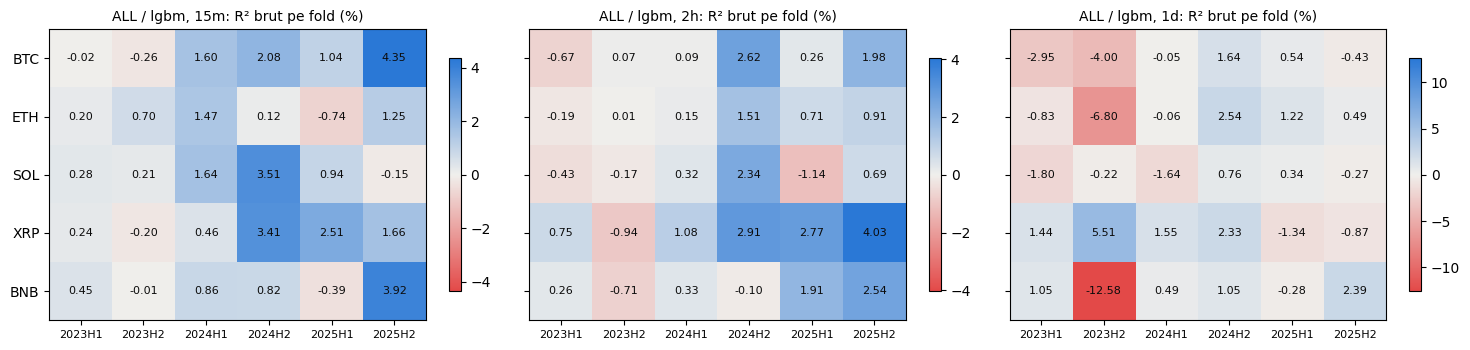

In [29]:
FR = M.fold_r2(P)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, h in zip(axes, ["15m", "2h", "1d"]):
    m = FR[(FR.set == "ALL") & (FR.model == "lgbm") & (FR.h == h) & (FR.ycol == f"y_{h}")].pivot(index="asset", columns="fold", values="r2") * 100
    m = m.reindex(M.ASSETS)
    v = max(np.nanmax(np.abs(m.values)), 0.05)
    from matplotlib.colors import LinearSegmentedColormap
    cmap = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
    im = ax.imshow(m.values, cmap=cmap, vmin=-v, vmax=v, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="#0b0b0b")
    ax.set_xticks(range(6)); ax.set_xticklabels([f"{p.year}H{1 if p.month == 1 else 2}" for p in M.TEST_STARTS], fontsize=8)
    ax.set_yticks(range(5)); ax.set_yticklabels(M.ASSETS)
    ax.set_title(f"ALL / lgbm, {h}: R² brut pe fold (%)", fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

In [30]:
print("R² pe fold (%), pooled, ținta principală — stabilitatea în timp")
f2 = M.fold_r2(P.assign(asset="ALL"))
f2 = f2[f2.ycol == "y_" + f2.h]
(f2.pivot_table(index=["h", "model", "set"], columns="fold", values="r2") * 100).round(3).loc[(slice(None), slice(None), ["PV", "OWN", "ALL"]), :]

R² pe fold (%), pooled, ținta principală — stabilitatea în timp


fold               0      1      2      3      4      5
h   model set                                          
15m lgbm  PV   0.416  0.129  0.826  3.229  1.744  2.744
    mean  PV   0.026  0.058  0.077  0.174  0.079  0.105
    ridge PV    0.03  0.257  0.742  1.666    0.6  0.751
1d  lgbm  PV  -1.659  0.101 -0.204  -1.32  1.704  1.837
    mean  PV  -2.323 -0.076  -0.51 -0.108  0.345 -0.005
    ridge PV   -2.32 -0.105 -0.493  2.892   2.11   0.24
2h  lgbm  PV  -0.307  0.184  0.725  2.526  0.549   1.72
    mean  PV  -0.216 -0.089  0.017  0.128  0.161  0.173
    ridge PV  -0.217 -0.086  0.285  0.776  0.854  1.717
15m lgbm  OWN  0.192  -0.03  0.622  2.638  1.823  2.225
    ridge OWN  0.036  0.604  0.776  1.211  0.428  1.175
1d  lgbm  OWN -1.143 -0.088 -0.502  0.969  1.001 -1.911
    ridge OWN -2.269  -2.84 -0.477  3.809  2.884  0.063
2h  lgbm  OWN -0.286 -0.352  0.437   2.65  0.359  1.749
    ridge OWN -0.212 -0.073  0.775  0.428  0.931  0.298
15m lgbm  ALL  0.188  -0.08  1.226  2.921  1.429   1.97
    ridge ALL  0.039  0.943   0.75  0.955  0.296  0.797
1d  lgbm  ALL -1.319  0.228 -0.547  1.952 -0.293  0.347
    ridge ALL  -2.24 -3.647 -0.453  3.479  3.884  0.152
2h  lgbm  ALL -0.162 -0.721  0.407   2.43  1.289  2.422
    ridge ALL -0.212 -0.068  0.725  0.612  1.253  0.427

In [31]:
print("Control bounce la 15 min: țintă de la t+1s (principală) vs de la t+60s; R² brut și scalat (%)")
b = pd.concat({"r2_brut": E.set_index(["h", "ycol", "model", "set", "scope"])["r2"],
               "r2_sigma": Es.set_index(["h", "ycol", "model", "set", "scope"])["r2"],
               "r2_drop10d": E.set_index(["h", "ycol", "model", "set", "scope"])["r2_drop10d"]}, axis=1).loc["15m"] * 100
b = b.loc[(slice(None), slice(None), ["PV", "OWN", "ALL"]), :].unstack("ycol")
b.round(3)

Control bounce la 15 min: țintă de la t+1s (principală) vs de la t+60s; R² brut și scalat (%)


r2_brut           r2_sigma           r2_drop10d          
ycol              y_15m y_15m_d60    y_15m y_15m_d60      y_15m y_15m_d60
model set scope                                                          
lgbm  PV  ALL     2.007      1.68    0.064     0.108      0.923     0.603
          BNB     2.956     3.031    -0.43    -0.146      0.666     0.558
          BTC     1.513     1.113    0.233      0.16      0.338     0.225
          ETH     0.517     0.732    0.023     0.006      0.638     0.301
          SOL     1.041     0.811    0.408      0.36      0.654     0.383
          XRP     2.526     1.947    0.099     0.147      1.011     0.718
      OWN ALL     1.701     1.306    0.081     0.136      0.686     0.451
          BNB      2.38     2.349   -0.358    -0.094      0.752     0.543
          BTC     1.372     0.945     0.29     0.184      0.315     0.182
          ETH     0.708     0.577    0.067    -0.014      0.666     0.303
          SOL     0.957     0.636     0.39      0.34      0.574     0.394
          XRP     2.078     1.503    0.069     0.212        0.9     0.402
      ALL ALL     1.676     1.228    0.062     0.071      0.755     0.359
          BNB     2.167     2.041   -0.391      -0.2      0.555     0.416
          BTC     1.396     0.779    0.301     0.128      0.311     0.099
          ETH     0.346     0.055   -0.032    -0.272      0.852     0.393
          SOL     1.283      0.57      0.4     0.271      0.512      0.21
          XRP     2.013     1.572    0.072     0.268      0.951     0.749
ridge PV  ALL      0.84       0.7     0.09     0.067      0.624     0.435
          BNB     0.734     0.732    0.019     0.056      0.466     0.403
          BTC      0.62     0.482    0.052     0.018      0.342     0.227
          ETH     0.549     0.385   -0.028    -0.109      0.379     0.205
          SOL     0.678     0.509    0.213     0.138      0.601     0.426
          XRP     1.012     0.854    0.146      0.15      0.806     0.527
      OWN ALL     0.852     0.455    0.066     0.066      0.552     0.255
          BNB     0.794     0.409   -0.047     0.045      0.571     0.403
          BTC     0.692     0.374    0.081     0.031      0.211      0.16
          ETH     0.739     0.414    0.038    -0.028       0.38     0.228
          SOL     0.853     0.571    0.241     0.164      0.539      0.31
          XRP     0.903     0.434    0.047     0.094       0.63     0.403
      ALL ALL     0.694     0.549     0.07     0.033      0.423     0.261
          BNB     0.616     0.598    0.005     0.024      0.463     0.371
          BTC     0.515     0.374    0.069     0.016      0.231     0.129
          ETH     0.563     0.332    0.002    -0.097      0.362     0.239
          SOL     0.739     0.553    0.211     0.135      0.421      0.28
          XRP     0.738     0.593     0.07      0.06      0.409     0.277

## 7. Relevanță economică (ipotetică)

Fără costuri reale, arătăm randamentul realizat pe chintile de predicție și o regulă minimă de semn, cu sensibilitate
la costuri dus-întors de 2 / 5 / 10 / 20 bps (pentru referință: taxa taker Binance spot standard este 10 bps pe parte,
deci ~20 bps dus-întors fără reduceri; un maker cu rabat poate fi aproape de 0, dar cu risc de neexecutare).
Pozițiile se suprapun, deci cifrele sunt medii per semnal, **nu** rezultatul unei strategii.

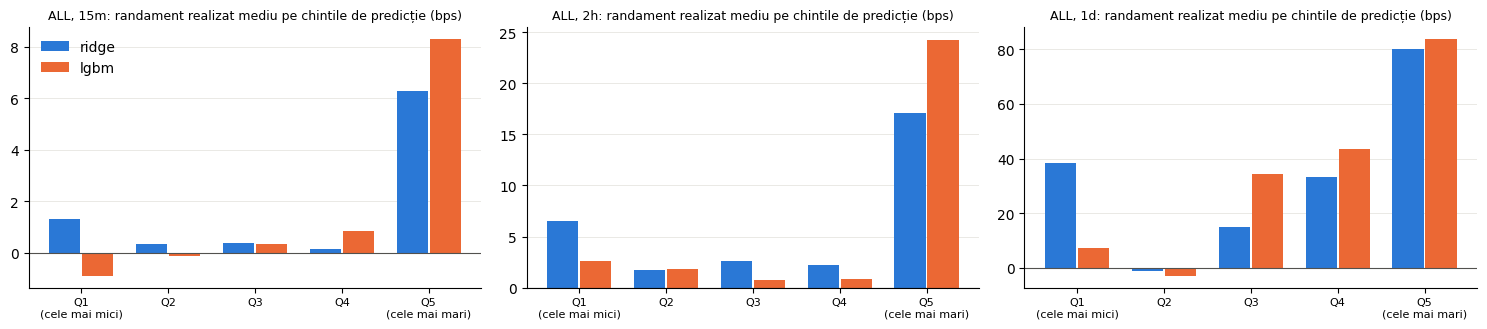

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, h in zip(axes, ["15m", "2h", "1d"]):
    for i, (mdl, col) in enumerate([("ridge", "#2a78d6"), ("lgbm", "#eb6834")]):
        s = P[(P.set == "ALL") & (P.model == mdl) & (P.h == h) & (P.ycol == f"y_{h}")].copy()
        s["q"] = s.groupby(["fold", "asset"])["pred_bps"].transform(lambda x: pd.qcut(x.rank(method="first"), 5, labels=False))
        g = s.groupby("q")["y_bps"].mean()
        ax.bar(np.arange(5) + (i - 0.5) * 0.38, g.values, width=0.36, color=col, label=mdl)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_xticks(range(5)); ax.set_xticklabels(["Q1\n(cele mai mici)", "Q2", "Q3", "Q4", "Q5\n(cele mai mari)"], fontsize=8)
    ax.set_title(f"ALL, {h}: randament realizat mediu pe chintile de predicție (bps)", fontsize=9)
    ax.grid(axis="y", color="#e6e5e0", lw=0.6); ax.set_axisbelow(True)
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

In [33]:
print("Randament mediu pe chintile de predicție (bps), pe active — set ALL, lgbm | ridge")
qq = []
for (mdl, h), s in P[(P.set == "ALL") & (P.ycol == "y_" + P.h)].groupby(["model", "h"]):
    s = s.copy()
    s["q"] = s.groupby(["fold", "asset"])["pred_bps"].transform(lambda x: pd.qcut(x.rank(method="first"), 5, labels=False)) + 1
    qq.append(s.groupby(["asset", "q"])["y_bps"].mean().unstack().assign(model=mdl, h=h))
pd.concat(qq).reset_index().set_index(["h", "model", "asset"]).sort_index().round(1)

Randament mediu pe chintile de predicție (bps), pe active — set ALL, lgbm | ridge


q                   1     2    3     4     5
h   model asset                             
15m lgbm  BNB    -0.8  -0.4 -0.1   0.2   4.1
          BTC    -0.4   0.4  0.3   0.6   4.6
          ETH      -1  -0.2  0.2   0.1   5.5
          SOL    -0.6  -0.4  0.3   0.3   9.5
          XRP    -1.6     0  0.8   2.8  15.9
    ridge BNB      -0   0.1  0.3  -0.4     3
          BTC     0.4  -0.1  0.2   0.5   4.5
          ETH     1.3  -0.3 -0.3  -0.4   4.3
          SOL     0.1  -0.1  0.2   0.2   8.7
          XRP     4.4   1.9  1.4   0.6   9.6
1d  lgbm  BNB    -9.9   -41 18.5  34.2  54.6
          BTC     5.5  19.2 39.9    35  64.2
          ETH   -35.4   -11 35.9  28.9  81.4
          SOL     2.5 -14.5 25.5  54.1  56.3
          XRP      64  28.9 50.1    59 153.7
    ridge BNB      31   7.6 12.3 -17.5    23
          BTC    67.8  23.4  9.9   8.8  53.9
          ETH    27.8 -30.7 -4.2  26.5  80.4
          SOL    36.8   4.5 -7.1  14.7    75
          XRP    31.8  -8.9 60.8   119 152.8
2h  lgbm  BNB     4.5  -1.1 -1.3  -5.3  15.9
          BTC    -2.1     1  3.3   6.2  12.5
          ETH    -2.5   2.9 -0.5  -1.1  15.4
          SOL    -0.2   2.2 -0.6  -1.8  20.6
          XRP    12.2   3.4  2.7   5.9    52
    ridge BNB    -2.9     2  0.5   2.8  10.5
          BTC     7.4   4.8  1.1   1.2   6.5
          ETH       1  -0.9 -0.5   1.4  13.2
          SOL     1.4  -1.9  1.2  -0.2  19.7
          XRP    23.5   5.2  9.8   5.9  31.8

In [34]:
EC = M.economics(P)
cols = ["trade_frac", "mean_abs_pred", "gross_all", "gross_sel", "gross_sel_se_daily", "gross_sel_drop10d", "days_pos",
        "net_2", "net_5", "net_10", "net_20", "net_10_drop10d"]
print("Regula semn(predicție), activă doar când |predicție| > cuantila 0.9 a |predicție| din antrenare (prag ex-ante).")
print("bps per decizie (pozițiile se suprapun; nu e backtest de portofoliu). net_c = brut − cost dus-întors c bps")
e = EC[(EC.ycol == "y_" + EC.h) & EC.set.isin(["PV", "OWN", "ALL"])].set_index(["h", "model", "set", "scope"])[cols]
e.reindex(pd.MultiIndex.from_product([["15m", "2h", "1d"], ["ridge", "lgbm"], ["PV", "OWN", "ALL"], ["ALL"] + M.ASSETS])).round(2)

Regula semn(predicție), activă doar când |predicție| > cuantila 0.9 a |predicție| din antrenare (prag ex-ante).
bps per decizie (pozițiile se suprapun; nu e backtest de portofoliu). net_c = brut − cost dus-întors c bps


trade_frac  mean_abs_pred  gross_all  gross_sel  gross_sel_se_daily  gross_sel_drop10d  days_pos  net_2  net_5  net_10  net_20  net_10_drop10d
15m ridge PV  ALL         0.1           2.25       1.26      10.54                1.31              13.97      0.73   8.54   5.54    0.54   -9.46            3.97
              BTC        0.03            1.1       0.97      15.62                2.58              15.02      0.74  13.62  10.62    5.62   -4.38            5.02
              ETH        0.06           1.74       0.41       8.99                2.08              10.54      0.75   6.99   3.99   -1.01  -11.01            0.54
              SOL        0.13           2.54       1.83      14.14                1.71              14.89       0.7  12.14   9.14    4.14   -5.86            4.89
              XRP         0.2           3.81       2.13       9.32                1.82              13.95      0.74   7.32   4.32   -0.68  -10.68            3.95
              BNB        0.07           1.68       0.67       6.12                2.02              14.06      0.72   4.12   1.12   -3.88  -13.88            4.06
          OWN ALL         0.1           2.49        1.3      10.12                1.61              13.61      0.73   8.12   5.12    0.12   -9.88            3.61
              BTC        0.03           1.23       1.19      15.04                3.25               11.2      0.69  13.04  10.04    5.04   -4.96             1.2
              ETH        0.05           1.87       0.96      12.48                 2.5              14.69      0.77  10.48   7.48    2.48   -7.52            4.69
              SOL        0.12           2.84       1.93      15.07                1.96              14.04      0.69  13.07  10.07    5.07   -4.93            4.04
              XRP         0.2           4.39       1.43       6.54                2.32               9.77      0.77   4.54   1.54   -3.46  -13.46           -0.23
              BNB        0.05           1.63       0.84       8.19                2.63              21.99      0.72   6.19   3.19   -1.81  -11.81           11.99
          ALL ALL         0.1           2.36       1.11       9.55                1.53               12.2      0.73   7.55   4.55   -0.45  -10.45             2.2
              BTC        0.03           1.18       1.16      17.14                3.57              10.36      0.69  15.14  12.14    7.14   -2.86            0.36
              ETH        0.05           1.72       0.58      11.03                2.46              14.08      0.75   9.03   6.03    1.03   -8.97            4.08
              SOL        0.12           2.73       1.69      14.19                1.91              12.01       0.7  12.19   9.19    4.19   -5.81            2.01
              XRP         0.2           4.17       1.26       5.95                2.43               9.21      0.75   3.95   0.95   -4.05  -14.05           -0.79
              BNB        0.05           1.54       0.67       8.33                2.86              19.92      0.75   6.33   3.33   -1.67  -11.67            9.92
    lgbm  PV  ALL         0.1           2.11       1.39      11.34                 1.1              13.03      0.59   9.34   6.34    1.34   -8.66            3.03
              BTC        0.07           1.12       0.71        7.4                 1.5               6.52      0.59    5.4    2.4    -2.6   -12.6           -3.48
              ETH        0.09           1.76       0.42       4.94                1.66                8.6      0.59   2.94  -0.06   -5.06  -15.06            -1.4
              SOL        0.11           2.02       1.79      15.48                1.86               11.7      0.56  13.48  10.48    5.48   -4.52             1.7
              XRP        0.15           3.54       3.07      16.25                2.01              16.68      0.58  14.25  11.25    6.25   -3.75            6.68
              BNB         0.1           1.81       0.56       5.35                1.62               8.88      0.59   3.35   0.35  

In [35]:
print("Același calcul pentru controlul bounce (15m de la t+60s)")
EC[EC.ycol == "y_15m_d60"].set_index(["model", "set", "scope"])[cols].round(2)

Același calcul pentru controlul bounce (15m de la t+60s)


trade_frac  mean_abs_pred  gross_all  gross_sel  gross_sel_se_daily  gross_sel_drop10d  days_pos  net_2  net_5  net_10  net_20  net_10_drop10d
model set scope                                                                                                                                                
lgbm  ALL ALL           0.1           1.97       1.59      10.91                1.15               9.06      0.59   8.91   5.91    0.91   -9.09           -0.94
          BNB          0.08           1.35       1.04       7.66                1.86                6.1      0.56   5.66   2.66   -2.34  -12.34            -3.9
          BTC          0.05           0.98       0.79       7.32                1.84               5.88      0.55   5.32   2.32   -2.68  -12.68           -4.12
          ETH          0.07           1.58       0.96       8.09                1.99                8.2       0.6   6.09   3.09   -1.91  -11.91            -1.8
          SOL          0.13           2.23       1.45       9.09                1.59               7.16      0.56   7.09   4.09   -0.91  -10.91           -2.84
          XRP          0.16           3.34       3.37      15.99                1.92              14.54      0.59  13.99  10.99    5.99   -4.01            4.54
ridge ALL ALL           0.1           2.01       0.85        7.3                1.32               9.33       0.7    5.3    2.3    -2.7   -12.7           -0.67
          BNB          0.06            1.3       0.74        8.1                2.44              15.95      0.74    6.1    3.1    -1.9   -11.9            5.95
          BTC          0.04           0.97       0.67      11.76                2.71               6.26      0.65   9.76   6.76    1.76   -8.24           -3.74
          ETH          0.06           1.45       0.38       8.37                2.29              11.39       0.7   6.37   3.37   -1.63  -11.63            1.39
          SOL          0.12           2.36       1.42      10.69                 1.7               8.58      0.67   8.69   5.69    0.69   -9.31           -1.42
          XRP           0.2           3.57       0.88       4.16                1.96               9.57      0.75   2.16  -0.84   -5.84  -15.84           -0.43
lgbm  OWN ALL          0.11            1.8        1.4       9.04                1.06               9.64      0.58   7.04   4.04   -0.96  -10.96           -0.36
          BNB          0.08           1.24       0.82        8.7                1.79               8.18      0.57    6.7    3.7    -1.3   -11.3           -1.82
          BTC          0.06           1.05        0.7       5.47                1.62               6.12      0.56   3.47   0.47   -4.53  -14.53           -3.88
          ETH          0.08           1.49       0.85       4.82                1.89               7.21      0.56   2.82  -0.18   -5.18  -15.18           -2.79
          SOL          0.12           1.89       1.51       8.79                1.61               7.65      0.56   6.79   3.79   -1.21  -11.21           -2.35
          XRP          0.16           3.02        2.8       12.3                1.92              12.13      0.59   10.3    7.3     2.3    -7.7            2.13
ridge OWN ALL           0.1            1.9       1.02       8.03                1.29               9.81      0.71   6.03   3.03   -1.97  -11.97           -0.19
          BNB          0.06            1.2       0.62       9.53                2.39              16.96      0.73   7.53   4.53   -0.47  -10.47            6.96
          BTC          0.04           0.92       1.01      13.99                2.62               8.48      0.67  11.99   8.99    3.99   -6.01           -1.52
          ETH          0.06            1.4       0.82        9.5                2.22              11.16      0.71    7.5    4.5    -0.5   -10.5            1.16
          SOL          0.12           2.21       1.54      12.67                 1.7              10.94      0.67  10.67   7.67    2.67   -7.33            0.94
          XRP    

## 8. Ce este, de fapt, semnalul PV de 15 minute? (explorator)

Coeficienții ridge (în medie pe folduri) cu semn pozitiv: numărul de tranzacții și mărimea medie a tranzacției relative
la ultimele 200 de bare (+0,077 / +0,072), creșterea vol 1h/1z, `lrv_1d`; cu semn negativ: durata relativă a barei
(barele rapide → randament pozitiv ulterior), `lrv_1h`, randamentul pe 5 min (reversal). Pe scurt: **după bare foarte
rapide, cu volum mare, în volatilitate mare — în special după scăderi — prețul tinde să crească în următoarele minute.**
Tabelele de mai jos arată că regula câștigă aproape numai pe partea long și că o parte din efect depinde de regimul de
piață al perioadei de test (2023–2025, predominant crescătoare).

In [36]:
def blockboot_mean(day, x, n=1000, block=20, seed=0):
    g = pd.DataFrame({"d": day, "x": x}).groupby("d")["x"].agg(["sum", "size"])
    S, N = g["sum"].values, g["size"].values; k = len(S); rng = np.random.default_rng(seed)
    nb = int(np.ceil(k / block)); st = rng.integers(0, k - block + 1, (n, nb))
    idx = (st[:, :, None] + np.arange(block)).reshape(n, -1)[:, :k]
    return np.percentile(S[idx].sum(1) / N[idx].sum(1), [2.5, 97.5])
rows = []
for (s, m, h) in [("PV", "ridge", "15m"), ("PV", "lgbm", "15m"), ("PV", "ridge", "2h"), ("PV", "lgbm", "2h"), ("PV", "ridge", "1d"), ("PV", "lgbm", "1d")]:
    S = P[(P.set == s) & (P.model == m) & (P.h == h) & (P.ycol == f"y_{h}")].copy()
    thr = {x["fold"]: x["train_abs_q"]["0.9"] for x in M.job_meta(s, m, h, f"y_{h}")}
    S = S[S.pred_bps.abs() > S.fold.map(thr)]
    S["pnl"] = np.sign(S.pred_bps) * S.y_bps
    lo, hi = blockboot_mean(S.day.values, S.pnl.values)
    r = dict(set=s, model=m, h=h, n_signals=len(S), days=S.day.nunique(), gross=S.pnl.mean(), ci_lo=lo, ci_hi=hi)
    for side, ss in S.groupby(S.pred_bps > 0):
        nm = "long" if side else "short"
        r[f"{nm}_share"] = len(ss) / len(S); r[f"{nm}_pnl"] = ss.pnl.mean()
        r[f"{nm}_lrv1h"] = d.lrv_1h.values[ss.row].mean(); r[f"{nm}_zr5m"] = d.zr_5m.values[ss.row].mean()
    r["worst_fold"] = S.groupby("fold").pnl.mean().min()
    rows.append(r)
print("Regula decilei extreme (prag ex-ante), descompusă pe direcție; CI = bootstrap pe blocuri de 20 de zile.")
print("lrv_1h mediu necondiționat:", round(float(d.lrv_1h.mean()), 2), "| zr_5m = randamentul pe 5 min în unități de volatilitate")
pd.DataFrame(rows).round(2)

Regula decilei extreme (prag ex-ante), descompusă pe direcție; CI = bootstrap pe blocuri de 20 de zile.
lrv_1h mediu necondiționat: -4.82 | zr_5m = randamentul pe 5 min în unități de volatilitate


,set,model,h,n_signals,days,gross,ci_lo,ci_hi,short_share,short_pnl,short_lrv1h,short_zr5m,long_share,long_pnl,long_lrv1h,long_zr5m,worst_fold
0,PV,ridge,15m,60671,768,10.54,4.17,16.25,0.13,-7.8,-3.92,0.66,0.87,13.31,-3.87,-1.91,5.45
1,PV,lgbm,15m,60160,960,11.34,3.98,17.85,0.17,-2.14,-3.68,0.29,0.83,14.13,-3.96,-0.98,0.25
2,PV,ridge,2h,57101,516,32.55,7.17,50.57,0.27,-19.3,-4.12,0.2,0.73,51.5,-3.73,-1.45,-44.44
3,PV,lgbm,2h,56568,710,35.36,13.87,55,0.38,-0.86,-3.82,0.11,0.62,57.55,-3.82,-0.73,-6.81
4,PV,ridge,1d,60423,265,124.7,-7.56,245.2,0.35,-58.67,-4.03,-0.06,0.65,223,-3.62,0.02,-138.1
5,PV,lgbm,1d,47795,403,68.73,-62.58,192.7,0.51,-105.5,-4.18,NaN,0.49,248,-3.9,-0.37,-3.86


In [37]:
# Descriptiv (fără model, EXPLORATOR: pragurile sunt alese după ce am văzut tabelul de mai sus).
# hv = decila superioară a lrv_1h în anul și activul respectiv; drop = zr_5m < -2. Include 2021–2022 (doar antrenare).
x = d[d.t_us < M.us(M.RESERVE_START)].copy()
x["year"] = pd.to_datetime(x.t_us, unit="us").dt.year
x["hv"] = x.groupby(["asset", "year"], observed=True).lrv_1h.transform(lambda s: s > s.quantile(0.9))
x["state"] = np.where(~x.hv, "vol normală", np.where(x.zr_5m < -2, "vol mare & scădere bruscă", "vol mare, fără scădere bruscă"))
tab = {yc: x.groupby(["year", "state"])[yc].mean().unstack() * 1e4 for yc in ["y_15m", "y_15m_d60", "y_2h"]}
print("randament mediu ulterior (bps) pe stări; BTC: 2022 = -64%, 2023 +156%, 2024 +120%, 2025 -6%")
pd.concat(tab, axis=1).round(1)

randament mediu ulterior (bps) pe stări; BTC: 2022 = -64%, 2023 +156%, 2024 +120%, 2025 -6%


y_15m                                                           y_15m_d60                                                                y_2h                                          
state vol mare & scădere bruscă vol mare, fără scădere bruscă vol normală vol mare & scădere bruscă vol mare, fără scădere bruscă vol normală vol mare & scădere bruscă vol mare, fără scădere bruscă vol normală
year                                                                                                                                                                                                             
2021                       32.2                           7.1         1.1                      27.5                           6.2         0.4                      73.6                          53.4        -0.1
2022                       24.4                          -2.3        -0.6                      20.6                            -2        -0.6                       5.3                         -21.4        -3.6
2023                       23.8                           7.6         1.2                      20.3                           6.8         0.9                      58.4                          36.1         3.9
2024                       65.3                           7.8         0.7                      61.4                           6.9         0.4                     114.8                          47.9         2.5
2025                       14.3                           3.3         0.2                      16.4                           3.1         0.1                      73.6                          36.4        -1.4

In [38]:
print(f"timp total notebook: {(time.time() - T0) / 60:.1f} min")

timp total notebook: 13.6 min


## 9. Concluzii

### 9.1 Harta datelor și limitele relevante
* **43 de dataseturi** (cu manifest), câte un tip de bară per director: volume / notional × ~25/50/100 bare/zi × 5
  active, plus build-uri vechi BTC de calibrare. ETH există doar în codul vechi, dar e echivalent. Fără time bars, fără ținte.
* **Familii utilizabile:** randamente, volatilitate, durată/intensitate, flux agresor, lambda Kyle/Hasbrouck,
  structurale, derivate (basis/premium index/funding), trend 30 z, premium Coinbase BTC/ETH (+ SOL; XRP din iulie 2023;
  BNB ~10%). **Nule sau aproape nule:** L2/cost/quotes, lichidări, ETF, Fear & Greed, skew; DVOL ~7%.
* **Limite reale:** (i) prețuri de tranzacție, nu mid; bounce-ul contează la 15 min pentru SOL/XRP/BNB în 2022–2023
  (pas de preț de până la 6,6 bps) și e tratat prin controlul t+60 s; (ii) eșantionare pe ceas de evenimente, cu pondere
  mai mare pentru perioadele active; (iii) praguri de bară calibrate pe toată perioada, cu efect numai asupra frecvenței;
  (iv) market-time replay: disponibilitatea minutului Coinbase e cea teoretică.

### 9.2 Tabelul comparabil (secțiunea 4) — citire
* **15 min:** toate seturile au R² brut pozitiv la toate activele (ridge 0,48–1,1%, LightGBM 0,3–3,3%). Diferențele dintre
  seturi sunt însă mai mici decât incertitudinea, iar `PV` e cel mai bun sau la egalitate. Pe scara scalată la risc,
  R² e de ordinul 0,03–0,46% pentru BTC/SOL, ~0 pentru ETH/XRP și negativ pentru BNB în LightGBM.
* **2 h:** R² brut pozitiv în medie (0,4–1,3% pooled), dar câștigul vine aproape integral din 10 zile (pondere
  0,7–1,0), iar R²σ ≈ 0; BTC, ETH și SOL sunt instabile între folduri.
* **1 zi:** semn instabil (BTC negativ în toate seturile, SOL în aproape toate), 1–4/6 folduri pozitive, R²σ negativ în
  majoritatea configurațiilor. R² brut pozitiv pentru ETH/XRP provine dintr-o pariere implicită pe trend (fold 0, 2023H1,
  e puternic negativ pentru toți), nu din informație stabilă.
* Media istorică (reper) are R² apropiat de 0 (0–0,2% la 15 min, negativ la 1 zi); modelele o bat la 15 min, nu și în mod fiabil la 1 zi.

### 9.3 Familii și orizont
* **Nicio familie nu aduce informație suplimentară demonstrată peste `PV`.** 0/42 de teste pooled trec Holm; 4/210
  comparații per activ au q_BH < 0,10, toate cu efect ≤ 0,12 pp după eliminarea a 10 zile.
* **Fluxul agresor / lambda** nu adaugă nimic la 15 min (LightGBM −0,30 pp, 1/6 folduri mai bune). Informația din fluxul
  barelor de eveniment, găsită anterior la secunde, nu supraviețuiește până la 15 min cu intrare la t+1 s.
* **Rolul se schimbă cu orizontul în ce folosește modelul, nu în ce câștigă în afara antrenării:** în LightGBM `ALL`,
  ponderea structuralelor scade de la 17% (15 min) la 0% (1 zi), cea a premium-ului Coinbase crește de la 13% la 45%,
  iar randamentele cross-asset ating maximul la 2 h (30%). Câștigurile OOS nu urmează însă importanța: premium-ul are
  ΔR² nesemnificativ și de semn instabil la 1 zi (−0,17 pp LightGBM / +0,09 pp ridge), iar cross-asset are semn negativ la 15 min / 2 h și pozitiv (fragil) doar la 1 zi.

### 9.4 Robust, fragil, fără avantaj
* **Robust (statistic, nu economic):** predictibilitate mică la **15 min din preț și volum**, la toate activele și în
  toate perioadele, care supraviețuiește corecției Holm, eliminării zilelor extreme și controlului bounce. Mărimea pe
  unitate de risc e foarte mică și o mare parte vine din câteva episoade de crash (10 octombrie 2025, 3 februarie 2025,
  decembrie 2024).
* **Fragil:** PV la 2 h; la 1 zi, randamentele cross-asset și structuralele în LightGBM; derivatele pentru BNB la 15 min;
  orice câștig economic la 2 h (un fold la −44 bps, susținut de partea long în volatilitate mare).
* **Fără avantaj demonstrat:** flux, lambda, structurale, derivate, premium Coinbase (propriu și BTC/ETH) și randamentele
  altor active, la toate cele trei orizonturi; seturile cumulative `OWN` și `ALL`; orizontul de 1 zi; câștigul economic
  net după costuri realiste de taker (≥ 15–20 bps dus-întors).

### 9.5 Un singur experiment următor
**Studiu de eveniment confirmator „revenire după capitulare” la 15 min, definit acum și rulat o singură dată pe date
nefolosite.**
* *De ce acesta:* este singura componentă care (a) apare în afara antrenării la toate activele și perioadele, (b) rezistă
  controlului bounce și (c) e prezentă descriptiv și în 2022, an de scădere. Componenta „volatilitate mare → randament
  pozitiv” depinde de regim și nu merită urmărită separat.
* *Definiție fixată înainte:* eveniment = bară închisă cu `zr_5m < −2` în timp ce `lrv_1h` e peste percentila 90 a
  propriilor ultime 90 de zile (prag cauzal); un singur eveniment per activ la 60 de minute (declusterizare); intrare la
  t+60 s; ieșire la 15 min (secundar 2 h). Repere: momente aleatoare în aceeași stare de volatilitate, fără scădere, și
  randamentul necondiționat.
* *Date:* perioada rezervată 2026-01-01 → 2026-09-01 (curată pentru ETH/SOL/XRP/BNB; pentru BTC văzută anterior în alt
  context) **și** date de după 2026-09-01, construite cu `update`.
* *Criteriu de succes, stabilit dinainte:* media declusterizată netă de 20 bps dus-întors > 0, cu CI bootstrap pe blocuri
  care exclude 0 la nivel pooled, și semn pozitiv la ≥ 4/5 active. Dacă nu e îndeplinit, **linia se oprește.**
  Execuția reală în panică (spread-uri lărgite) rămâne neverificată fără cotații bid/ask. O confirmare statistică ar
  justifica abia apoi colectarea de cotații, nu o strategie.
* **Nu recomand** continuarea familiilor suplimentare, a orizontului de 1 zi sau o căutare de hiperparametri pe
  configurațiile de aici.